<a href="https://colab.research.google.com/github/mariacastrom00/AI_exercises_MJCM/blob/main/project_MariaCastro_ViktorLundvall.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task A: Descriptive analysis

The descriptive analysis examines FLOW and the average speed in the sensor data from 2021. Summary statistics and histograms are used to describe distribution and time profiles show the traffic changes during the registered hours.

The morning peak is between 07:30-08:30. The traffic conditions are not uniform across the network which can be seen from the sensor averages. Before further analysis, missing observations, time gaps, incomplete daily recods and absernt observations are examined. Absent observation is not the same as a measured zero, zeros are not automatically errors.

Plots are used to see patterns, NOT CAUSES OF TRAFFIC VARIATION.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from google.colab import files
from IPython.display import display
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")

pd.set_option("display.max_columns", None)

# Loading the 2021 TRAINING dataset
filename = "training_dataset.csv"
if not Path(filename).is_file() and Path("upload", filename).is_file():
    filename = str(Path("upload", filename))
if not Path(filename).is_file():
    from google.colab import files
    files.upload()

# Load CSV
df_train = pd.read_csv(filename, sep=";")

# Check the loaded dataset
print("Loaded file:", filename)
print("Shape:", df_train.shape)
print("Date range:", df_train["Date"].min(), "to", df_train["Date"].max())

print("Unique sensors:", df_train["DP_ID"].nunique())
print("Unique portals:", df_train["PORTAL"].nunique())
print("Unique dates:", df_train["Date"].nunique())

Loaded file: training_dataset.csv
Shape: (1921967, 11)
Date range: 20210601 to 20211231
Unique sensors: 29
Unique portals: 8
Unique dates: 214


In [ ]:
# Creating the datetime variable
df_train["datetime"] = pd.to_datetime(
    df_train["Date"].astype(str) + " " + df_train["Time"].astype(str),
    format="%Y%m%d %H:%M:%S")

# Sorting observations by sensor and time
df_train = df_train.sort_values(
    ["DP_ID", "datetime"]).reset_index(drop=True)

print("Datetime range:")
print(df_train["datetime"].min(), "to", df_train["datetime"].max())

display(df_train.head())

Datetime range:
2021-06-01 04:00:00 to 2021-12-31 10:00:00


,DP_ID,PORTAL,Date,Time,Interval_1,Interval_5,Interval_15,Interval_30,Interval_60,SPEED_MS_AVG,FLOW,datetime
0,153,"E4S 56,490",20210601,04:00:00,240,48,16,8,4,27.50,1.0,2021-06-01 04:00:00
1,153,"E4S 56,490",20210601,04:01:00,241,48,16,8,4,25.57,11.0,2021-06-01 04:01:00
2,153,"E4S 56,490",20210601,04:02:00,242,48,16,8,4,23.83,12.0,2021-06-01 04:02:00
3,153,"E4S 56,490",20210601,04:03:00,243,48,16,8,4,24.59,10.0,2021-06-01 04:03:00
4,153,"E4S 56,490",20210601,04:04:00,244,48,16,8,4,27.36,5.0,2021-06-01 04:04:00


In [ ]:
print("FLOW zeros:", (df_train["FLOW"] == 0).sum())
print("SPEED zeros:", (df_train["SPEED_MS_AVG"] == 0).sum())

FLOW zeros: 0
SPEED zeros: 2


In [ ]:
print(df_train["datetime"].min())
print(df_train["datetime"].max())

2021-06-01 04:00:00
2021-12-31 10:00:00


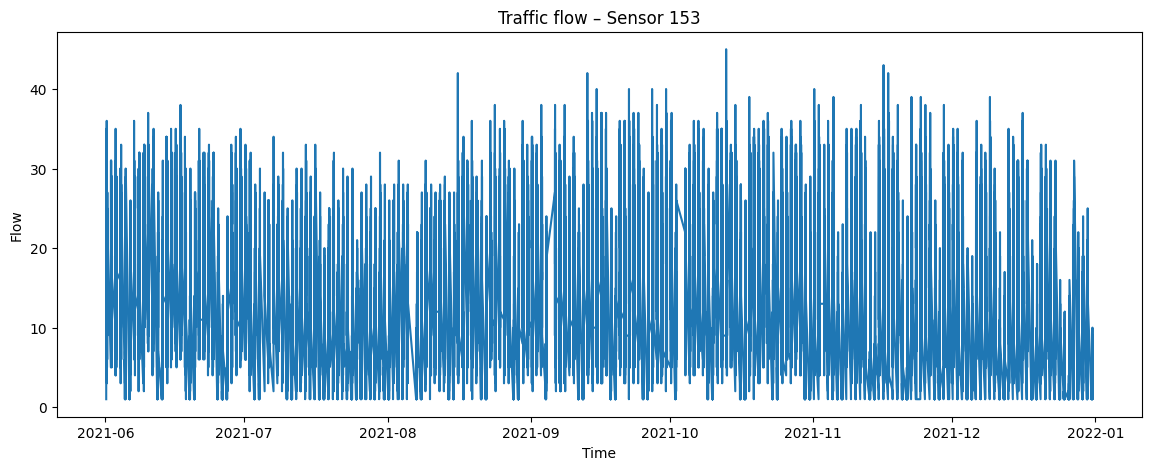

In [ ]:
sensor = df_train["DP_ID"].iloc[0]

sensor_df = df_train[df_train["DP_ID"] == sensor].copy()

plt.figure(figsize=(14, 5))

plt.plot(sensor_df["datetime"],
    sensor_df["FLOW"])

plt.xlabel("Time")
plt.ylabel("Flow")
plt.title(f"Traffic flow – Sensor {sensor}")

plt.show()

In [ ]:
df_train["hour"] = df_train["datetime"].dt.hour
df_train["minute"] = df_train["datetime"].dt.minute
df_train["day_of_week"] = df_train["datetime"].dt.dayofweek

In [ ]:
morning = df_train[(df_train["hour"] == 7) |
    ((df_train["hour"] == 8) & (df_train["minute"] == 0))]

In [ ]:
print("Shape:", df_train.shape)
print("Unique sensors:", df_train["DP_ID"].nunique())
print("Unique portals:", df_train["PORTAL"].nunique())
print("Unique dates:", df_train["Date"].nunique())
print("Date range:", df_train["Date"].min(), "to", df_train["Date"].max())

print("\nMissing values:")
print(df_train.isna().sum())

print("\nFLOW zeros:", (df_train["FLOW"] == 0).sum())
print("SPEED zeros:", (df_train["SPEED_MS_AVG"] == 0).sum())

Shape: (1921967, 15)
Unique sensors: 29
Unique portals: 8
Unique dates: 214
Date range: 20210601 to 20211231

Missing values:
DP_ID            0
PORTAL           0
Date             0
Time             0
Interval_1       0
Interval_5       0
Interval_15      0
Interval_30      0
Interval_60      0
SPEED_MS_AVG     0
FLOW            62
datetime         0
hour             0
minute           0
day_of_week      0
dtype: int64

FLOW zeros: 0
SPEED zeros: 2


In [ ]:
print("Date range:", df_train["Date"].min(), "to", df_train["Date"].max())
print("Number of dates:", df_train["Date"].nunique())
print("Number of sensors:", df_train["DP_ID"].nunique())
print("Number of portals:", df_train["PORTAL"].nunique())

Date range: 20210601 to 20211231
Number of dates: 214
Number of sensors: 29
Number of portals: 8


In [ ]:
print("Shape: ", df_train.shape)

print("\nColumns: ")
print(df_train.columns.tolist())

print("\nMissing values: ")
display(df_train.isna().sum())

print("\nFLOW = 0:")
print((df_train["FLOW"] == 0).sum())

print("\nSPEED = 0:")
print((df_train["SPEED_MS_AVG"] == 0).sum())

Shape:  (1921967, 15)

Columns: 
['DP_ID', 'PORTAL', 'Date', 'Time', 'Interval_1', 'Interval_5', 'Interval_15', 'Interval_30', 'Interval_60', 'SPEED_MS_AVG', 'FLOW', 'datetime', 'hour', 'minute', 'day_of_week']

Missing values: 


,0
DP_ID,0
PORTAL,0
Date,0
Time,0
Interval_1,0
Interval_5,0
Interval_15,0
Interval_30,0
Interval_60,0
SPEED_MS_AVG,0



FLOW = 0:
0

SPEED = 0:
2


In [ ]:
# Creating datetime column
df_train["datetime"] = pd.to_datetime(
    df_train["Date"].astype(str) + " " + df_train["Time"].astype(str),
    format="%Y%m%d %H:%M:%S")

# Sorting by sensor and time
df_train = df_train.sort_values(["DP_ID", "datetime"]).reset_index(drop=True)

# Checking the result
print("Earliest:", df_train["datetime"].min())
print("Latest:", df_train["datetime"].max())

display(df_train[["DP_ID", "Date", "Time", "datetime", "FLOW", "SPEED_MS_AVG"]].head())

Earliest: 2021-06-01 04:00:00
Latest: 2021-12-31 10:00:00


,DP_ID,Date,Time,datetime,FLOW,SPEED_MS_AVG
0,153,20210601,04:00:00,2021-06-01 04:00:00,1.0,27.50
1,153,20210601,04:01:00,2021-06-01 04:01:00,11.0,25.57
2,153,20210601,04:02:00,2021-06-01 04:02:00,12.0,23.83
3,153,20210601,04:03:00,2021-06-01 04:03:00,10.0,24.59
4,153,20210601,04:04:00,2021-06-01 04:04:00,5.0,27.36


In [ ]:
# Time features
df_train["hour"] = df_train["datetime"].dt.hour
df_train["minute"] = df_train["datetime"].dt.minute
df_train["day_of_week"] = df_train["datetime"].dt.dayofweek

# Minutes after midnight
df_train["time_minutes"] = (
    df_train["hour"] * 60 + df_train["minute"])

display(df_train[
        ["datetime", "hour", "minute", "day_of_week", "time_minutes"]].head())

,datetime,hour,minute,day_of_week,time_minutes
0,2021-06-01 04:00:00,4,0,1,240
1,2021-06-01 04:01:00,4,1,1,241
2,2021-06-01 04:02:00,4,2,1,242
3,2021-06-01 04:03:00,4,3,1,243
4,2021-06-01 04:04:00,4,4,1,244


In [ ]:
# Basic statistics for FLOW
print("FLOW statistics:")
display(df_train["FLOW"].describe())

# Basic statistics for SPEED
print("\nSPEED_MS_AVG statistics:")
display(df_train["SPEED_MS_AVG"].describe())

FLOW statistics:


,FLOW
count,1.921905e+06
mean,1.236552e+01
std,8.023255e+00
min,1.000000e+00
25%,5.000000e+00
50%,1.200000e+01
75%,1.900000e+01
max,4.500000e+01



SPEED_MS_AVG statistics:


,SPEED_MS_AVG
count,1.921967e+06
mean,2.002764e+01
std,3.027135e+00
min,0.000000e+00
25%,1.809000e+01
50%,1.985000e+01
75%,2.194000e+01
max,4.583000e+01


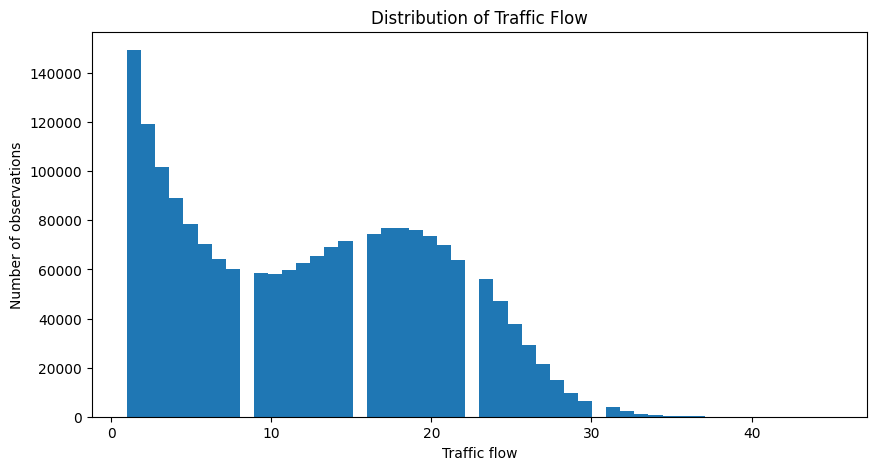

In [ ]:
# FLOW distribution
plt.figure(figsize=(10, 5))
plt.hist(df_train["FLOW"].dropna(), bins=50)
plt.xlabel("Traffic flow")
plt.ylabel("Number of observations")
plt.title("Distribution of Traffic Flow")
plt.show()

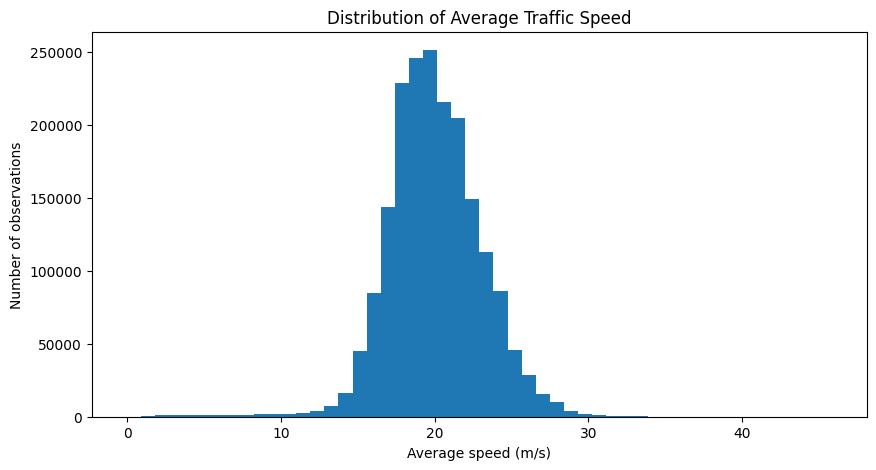

In [ ]:
# Speed distribution
plt.figure(figsize=(10, 5))
plt.hist(df_train["SPEED_MS_AVG"].dropna(), bins=50)
plt.xlabel("Average speed (m/s)")
plt.ylabel("Number of observations")
plt.title("Distribution of Average Traffic Speed")
plt.show()

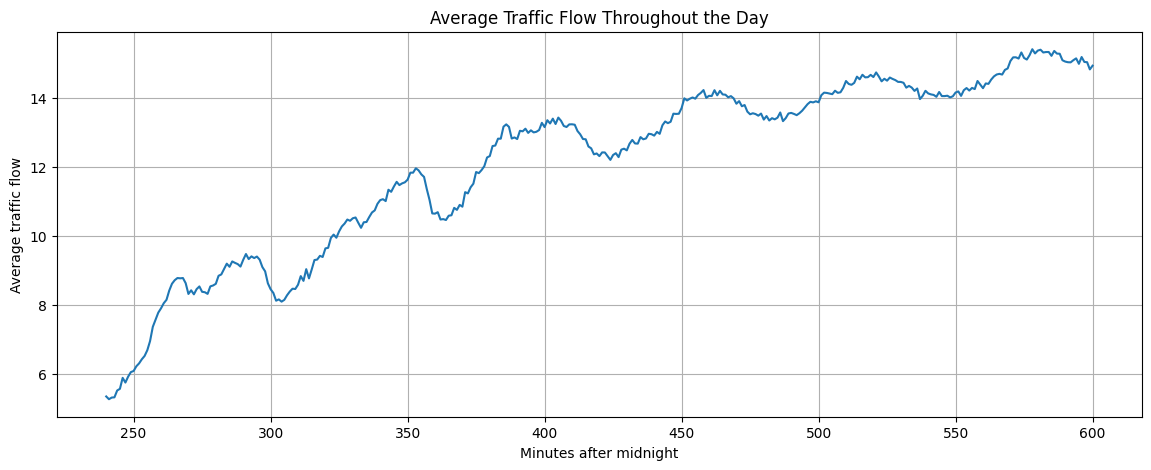

In [ ]:
# Average traffic flow for each minute of the day
hourly_flow = (df_train.groupby("time_minutes")["FLOW"].mean())

plt.figure(figsize=(14, 5))
plt.plot(hourly_flow.index, hourly_flow.values)

plt.xlabel("Minutes after midnight")
plt.ylabel("Average traffic flow")
plt.title("Average Traffic Flow Throughout the Day")
plt.grid(True)

plt.show()

In [ ]:
# Morning peak: 07:30–08:30
morning_peak = df_train[(df_train["time_minutes"] >= 450) &
    (df_train["time_minutes"] <= 510)].copy()

print("Morning peak observations:", len(morning_peak))

print("\nAverage flow:")
print(morning_peak["FLOW"].mean())

print("\nAverage speed (m/s):")
print(morning_peak["SPEED_MS_AVG"].mean())

print("\nAverage speed (km/h):")
print(morning_peak["SPEED_MS_AVG"].mean() * 3.6)

Morning peak observations: 347657

Average flow:
13.833064864087444

Average speed (m/s):
19.601087393609223

Average speed (km/h):
70.5639146169932


In [ ]:
# Average flow for each sensor
sensor_flow = (df_train.groupby("DP_ID")["FLOW"]
    .mean().sort_values(ascending=False))

print("Number of sensors:", len(sensor_flow))

display(sensor_flow)

Number of sensors: 29


,FLOW
DP_ID,
740,19.139047
749,19.015990
751,17.740933
1079,16.912481
902,16.554705
543,15.133467
353,14.821671
1076,14.651378
4430,14.094263


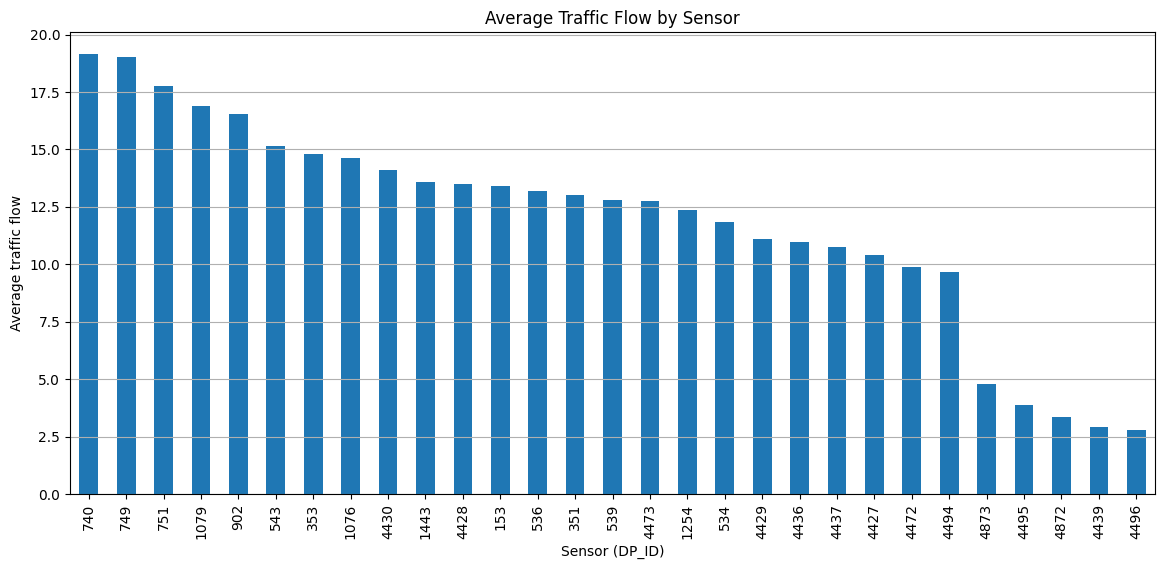

In [ ]:
plt.figure(figsize=(14, 6))

sensor_flow.plot(kind="bar")

plt.xlabel("Sensor (DP_ID)")
plt.ylabel("Average traffic flow")
plt.title("Average Traffic Flow by Sensor")
plt.xticks(rotation=90)
plt.grid(axis="y")

plt.show()

In [ ]:
sensor_speed = (df_train.groupby("DP_ID")["SPEED_MS_AVG"]
    .mean().sort_values(ascending=False))

display(sensor_speed)

,SPEED_MS_AVG
DP_ID,
4472,25.602116
536,23.294422
153,23.180928
4427,23.173537
4429,22.966745
1254,22.697915
4473,21.616659
4428,21.356614
4495,21.198660


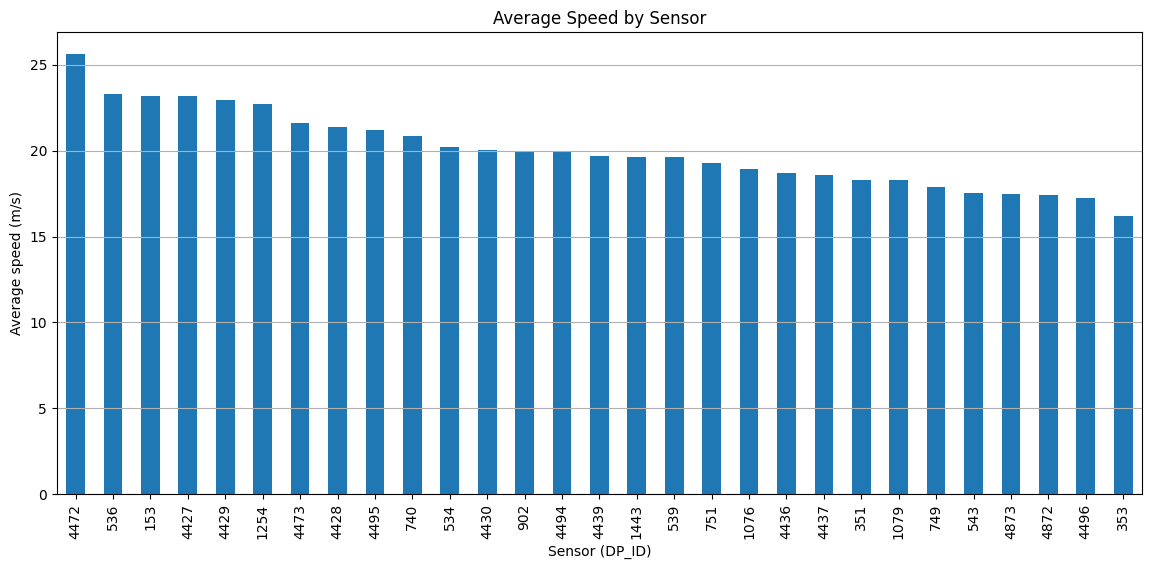

In [ ]:
plt.figure(figsize=(14, 6))

sensor_speed.plot(kind="bar")

plt.xlabel("Sensor (DP_ID)")
plt.ylabel("Average speed (m/s)")
plt.title("Average Speed by Sensor")
plt.xticks(rotation=90)
plt.grid(axis="y")

plt.show()

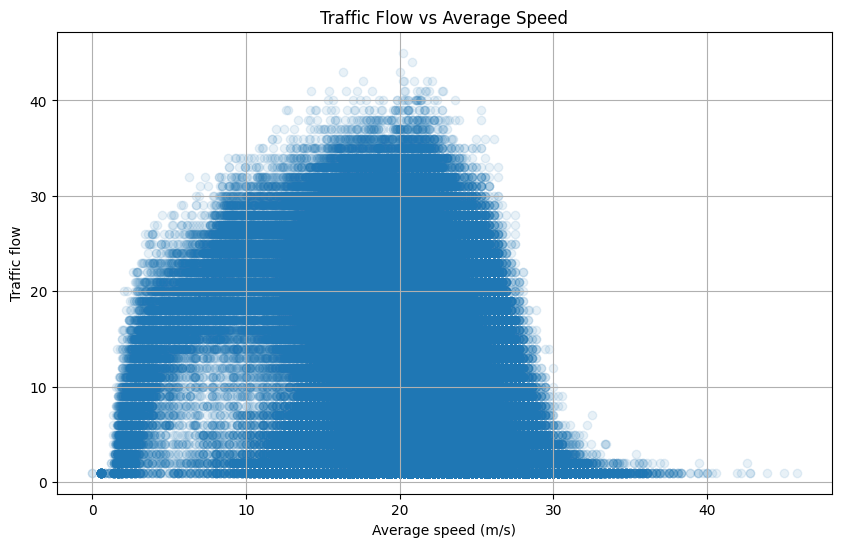

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(df_train["SPEED_MS_AVG"],
    df_train["FLOW"],
    alpha=0.1)

plt.xlabel("Average speed (m/s)")
plt.ylabel("Traffic flow")
plt.title("Traffic Flow vs Average Speed")

plt.grid(True)
plt.show()

In [ ]:
correlation = df_train[["FLOW", "SPEED_MS_AVG"]].corr()

display(correlation)

,FLOW,SPEED_MS_AVG
FLOW,1.000000,-0.274743
SPEED_MS_AVG,-0.274743,1.000000


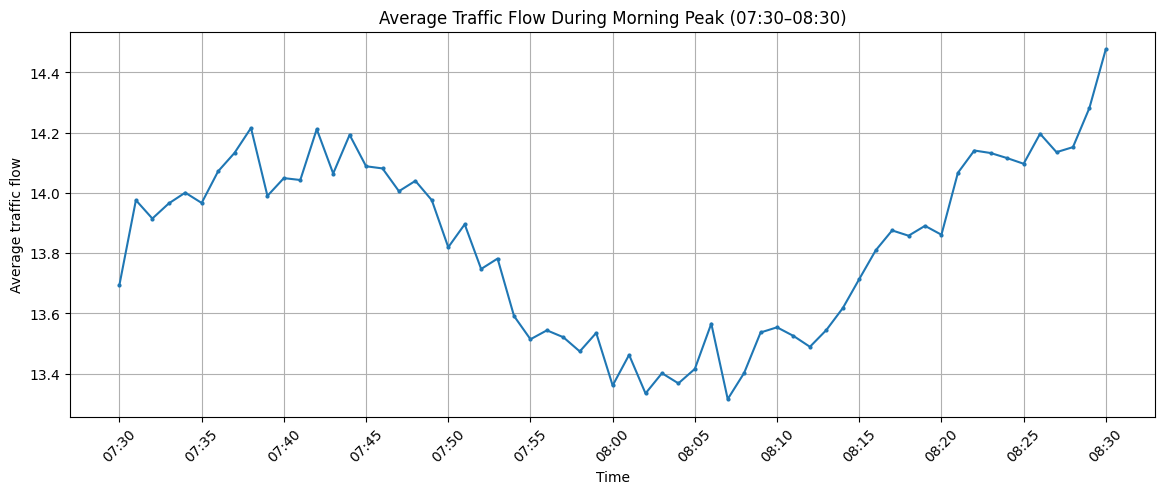

In [ ]:
# Average flow for each minute during the morning peak
morning_flow = (morning_peak.groupby("time_minutes")["FLOW"].mean())

# Creating time labels: 07:30, 07:31, ..., 08:30
time_labels = [f"{int(m // 60):02d}:{int(m % 60):02d}"
    for m in morning_flow.index]

plt.figure(figsize=(14, 5))

plt.plot(time_labels,
    morning_flow.values,
    marker="o",
    markersize=2)

plt.xlabel("Time")
plt.ylabel("Average traffic flow")
plt.title("Average Traffic Flow During Morning Peak (07:30–08:30)")

# Show every 5th label so the x-axis doesn't become crowded
plt.xticks(range(0, len(time_labels), 5),
    rotation=45)

plt.grid(True)
plt.show()

In [ ]:
# Average FLOW per sensor during the morning peak
morning_sensor_flow = (morning_peak.groupby("DP_ID")["FLOW"]
    .mean()
    .sort_values(ascending=False))

display(morning_sensor_flow)

,FLOW
DP_ID,
740,21.162143
749,21.054179
751,19.697512
1079,18.683155
4430,18.186957
902,18.016611
4428,17.352923
543,17.164287
353,16.821572


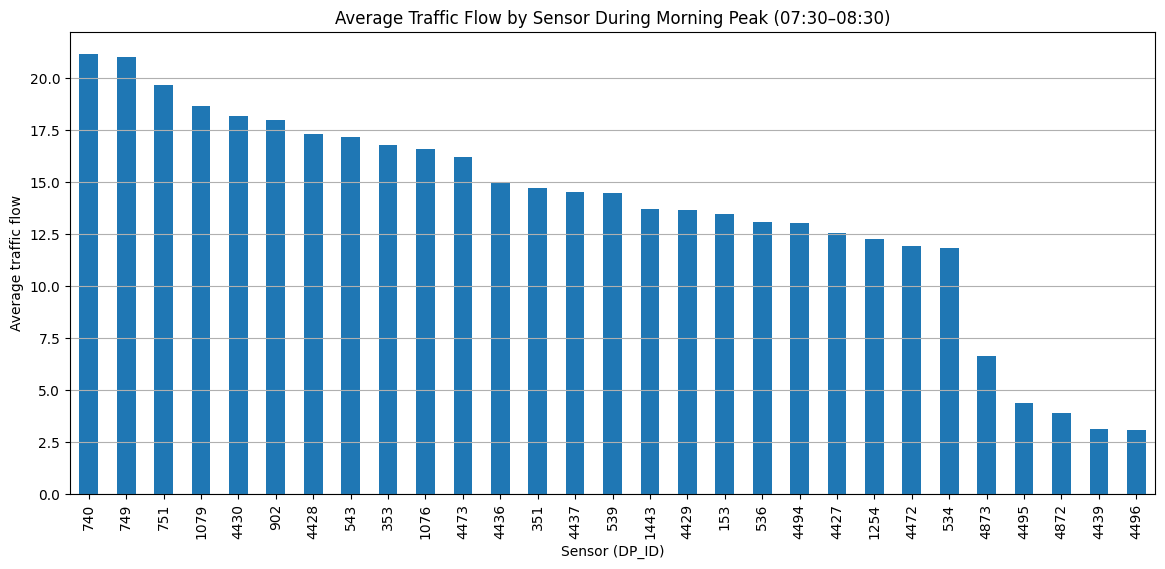

In [ ]:
plt.figure(figsize=(14, 6))

morning_sensor_flow.plot(kind="bar")

plt.xlabel("Sensor (DP_ID)")
plt.ylabel("Average traffic flow")
plt.title("Average Traffic Flow by Sensor During Morning Peak (07:30–08:30)")
plt.xticks(rotation=90)
plt.grid(axis="y")

plt.show()

In [ ]:
# Average SPEED per sensor during the morning peak
morning_sensor_speed = (morning_peak.groupby("DP_ID")["SPEED_MS_AVG"]
    .mean().sort_values(ascending=False))

display(morning_sensor_speed)

,SPEED_MS_AVG
DP_ID,
4472,25.292833
536,22.904940
4427,22.815690
153,22.738008
4429,22.471122
1254,22.400038
4473,21.064538
4495,20.789076
4428,20.734131


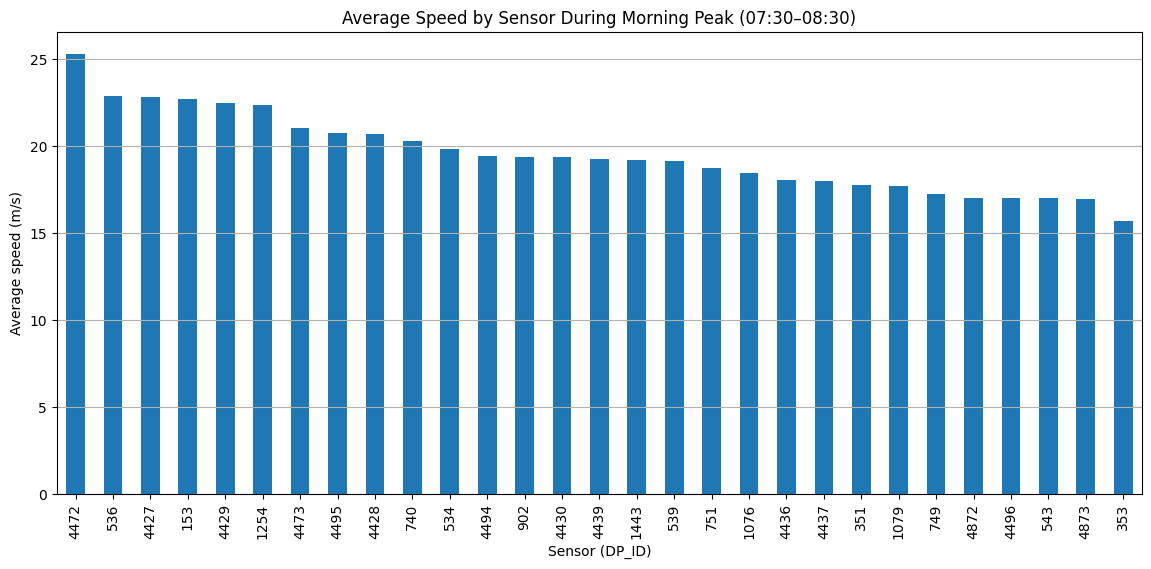

In [ ]:
plt.figure(figsize=(14, 6))

morning_sensor_speed.plot(kind="bar")

plt.xlabel("Sensor (DP_ID)")
plt.ylabel("Average speed (m/s)")
plt.title("Average Speed by Sensor During Morning Peak (07:30–08:30)")
plt.xticks(rotation=90)
plt.grid(axis="y")

plt.show()

# Task B: Problem formulation

Aim to investigate traffic regime aware short term traffic FLOW prediction during the morning peak. Main research question is whether training fitted traffic state clustering improves prediction at exactly fifteen minutes ahead.


Multi-output regression proble, supplemented by unsupervised clustering. Each sensor and prediction origin t, the models use sixteen observations from t-15 through t for both FLOW and SPEED --> 32 local input features. Targets: 15 separate FLOW observations at t+1, ..., t+15. They are not the sum of traffic over fifteen minutes. Speed is used as an input, not as a prediction target.


Feature hypotheses: Recent FLOW captures persistence, recent speed helps describe changing conditions, same portal measurements add local information, and network level states may distinguish patterns with different predicition difficulty. Error is also expected to depend on horizon, sensor and traffic state.


Chronological split uses:
June–October 2021 for training.
November–December 2021 for development validation.

There are 107,407 training examples and 40,111 validation examples. Their actual prediction origins are 07:45–08:15: because the input data are first restricted to 07:30–08:30, fifteen earlier minutes are unavailable for origins before 07:45.

The first 2022 evaluation uses the same 07:45–08:15 origin period. D6 retains a 07:15 historical buffer and therefore also includes origins from 07:30. This difference in evaluation cohorts must be reported. Comparisons between models within each cohort remain matched, but performance differences between files cannot be attributed solely to the dates.


Retrospective setup assumes that measurements at t are available when the forecast is issued. Real time use would require verification of sensor publication delay. The project is limited to horizons of 1–15 minutes; 30/60-minute forecasts are outside this formulation.

In [ ]:
# B1. Sensor and portal structure

# Identifying which sensors belong to each portal
sensor_portal = (df_train[["DP_ID", "PORTAL"]]
    .drop_duplicates()
    .sort_values(["PORTAL", "DP_ID"]))

print("Number of unique sensors: ", df_train["DP_ID"].nunique())
print("Number of unique portals: ", df_train["PORTAL"].nunique())

print("\nSensors per portal: ")
display(sensor_portal
    .groupby("PORTAL")["DP_ID"]
    .count()
    .sort_values(ascending=False))

print("\nSensor–portal mapping: ")
display(sensor_portal)

Number of unique sensors:  29
Number of unique portals:  8

Sensors per portal: 


,DP_ID
PORTAL,
"E4S 58,140",5
"E4S 56,780",4
"E4S 57,820",4
"E4S 56,490",4
"E4S 55,620",3
"E4S 56,160",3
"E4S 57,435",3
"E4S 57,055",3



Sensor–portal mapping: 


,DP_ID,PORTAL
642457,751,"E4S 55,620"
790591,1076,"E4S 55,620"
938483,1254,"E4S 55,620"
277662,536,"E4S 56,160"
347092,539,"E4S 56,160"
494426,740,"E4S 56,160"
0,153,"E4S 56,490"
70069,351,"E4S 56,490"
716658,902,"E4S 56,490"
1868343,4873,"E4S 56,490"


In [ ]:
# B2. Definition of the morning peak

# Keeping only observations from the morning peak period: 07:30–08:30
df_morning = df_train[(df_train["time_minutes"] >= 450) &
    (df_train["time_minutes"] <= 510)].copy()

print("Morning peak period: 07:30–08:30")
print("Morning peak shape: ", df_morning.shape)
print("Number of sensors: ", df_morning["DP_ID"].nunique())
print("Number of portals: ", df_morning["PORTAL"].nunique())
print("Number of dates: ", df_morning["datetime"].dt.date.nunique())

print("\nDate range:",
    df_morning["datetime"].min(),
    "to",
    df_morning["datetime"].max())

Morning peak period: 07:30–08:30
Morning peak shape:  (347657, 16)
Number of sensors:  29
Number of portals:  8
Number of dates:  214

Date range: 2021-06-01 07:30:00 to 2021-12-31 08:30:00


In [ ]:
# B3. Data quality and missing observations

# Number of observations during the morning peak for each sensor
observations_per_sensor = (df_morning
    .groupby("DP_ID")["datetime"]
    .nunique()
    .sort_values())

print("Observations per sensor: ")
display(observations_per_sensor)

Observations per sensor: 


,datetime
DP_ID,
4494,8955
4436,9106
4873,10611
4496,10852
4872,11164
351,11211
4430,11286
4439,11448
4472,12022


In [ ]:
print("Summary of observations per sensor: ")
display(observations_per_sensor.describe())

Summary of observations per sensor: 


,datetime
count,29.000000
mean,11988.172414
std,1034.424100
min,8955.000000
25%,11448.000000
50%,12424.000000
75%,12606.000000
max,12949.000000


In [ ]:
# Calculating time gaps between consecutive observations for each sensor
time_gaps = (df_morning
    .sort_values(["DP_ID", "datetime"])
    .groupby("DP_ID")["datetime"]
    .diff())

print("Most common time gaps: ")
display(time_gaps.value_counts().head(10))

Most common time gaps: 


,count
datetime,
0 days 00:01:00,334566
0 days 23:00:00,5421
0 days 00:02:00,5401
0 days 00:03:00,1091
0 days 00:04:00,373
0 days 23:01:00,180
0 days 00:05:00,118
1 days 23:00:00,83
0 days 00:06:00,76


In [ ]:
# Identifying gaps longer than one minute
large_gaps = time_gaps[time_gaps > pd.Timedelta(minutes=1)]

print("Number of gaps larger than 1 minute: ", len(large_gaps))
print("Largest gap: ", large_gaps.max())

Number of gaps larger than 1 minute:  13062
Largest gap:  37 days 23:41:00


In [ ]:
# Categorize gaps by length
gap_categories = pd.Series({"2–5 minutes": (
        (large_gaps > pd.Timedelta(minutes=1)) &
        (large_gaps <= pd.Timedelta(minutes=5))).sum(),

    "6–15 minutes": ((large_gaps > pd.Timedelta(minutes=5)) &
        (large_gaps <= pd.Timedelta(minutes=15))).sum(),

    "16–60 minutes": ((large_gaps > pd.Timedelta(minutes=15)) &
        (large_gaps <= pd.Timedelta(minutes=60))).sum(),

    "1–24 hours": ((large_gaps > pd.Timedelta(hours=1)) &
        (large_gaps <= pd.Timedelta(hours=24))).sum(),

    "More than 24 hours": (large_gaps > pd.Timedelta(hours=24)).sum()})

print("Gaps longer than one minute by category:")
display(gap_categories)

Gaps longer than one minute by category:


,0
2–5 minutes,6983
6–15 minutes,160
16–60 minutes,14
1–24 hours,5784
More than 24 hours,121


In [ ]:
# Number of observations for each sensor and day
daily_counts = (df_morning
    .groupby([
        "DP_ID",
        df_morning["datetime"].dt.date]).size())

print("Expected observations per sensor per day: ", 61)

print("\nDays with fewer than 61 observations: ")
print((daily_counts < 61).sum())

print("\nDays with exactly 61 observations: ")
print((daily_counts == 61).sum())

print("\nDays with more than 61 observations: ")
print((daily_counts > 61).sum())

Expected observations per sensor per day:  61

Days with fewer than 61 observations: 
1458

Days with exactly 61 observations: 
4476

Days with more than 61 observations: 
0


In [ ]:
# Missing values during the morning peak

missing_morning = df_morning[["FLOW", "SPEED_MS_AVG"]].isna().sum()

print("Missing values during the morning peak:")
display(missing_morning)

print("\nPercentage of missing values:")
display((df_morning[["FLOW", "SPEED_MS_AVG"]].isna().mean() * 100))

Missing values during the morning peak:


,0
FLOW,7
SPEED_MS_AVG,0



Percentage of missing values:


,0
FLOW,0.002013
SPEED_MS_AVG,0.000000


In [ ]:
# B4. Forecasting problem

# Predicting origins during the morning peak
prediction_origins = df_morning[
    (df_morning["time_minutes"] >= 450) &
    (df_morning["time_minutes"] <= 495)].copy()

print("Prediction origin period: 07:30–08:15")
print("Number of potential prediction origins:", len(prediction_origins))

print("\nPrediction horizon: 15 minutes")

print("For each prediction origin, the model predicts FLOW for the following 15 minutes.")

Prediction origin period: 07:30–08:15
Number of potential prediction origins: 261561

Prediction horizon: 15 minutes
For each prediction origin, the model predicts FLOW for the following 15 minutes.


In [ ]:
# B4.2 Input features and target variables

flow_features = ([f"FLOW_t-{i}" for i in range(15, 0, -1)]
    + ["FLOW"])

speed_features = ([f"SPEED_t-{i}" for i in range(15, 0, -1)]
    + ["SPEED_MS_AVG"])

target_columns = [f"FLOW_t+{i}" for i in range(1, 16)]

print("Number of FLOW input features: ", len(flow_features))
print("Number of SPEED input features: ", len(speed_features))
print("Total input features: ", len(flow_features) + len(speed_features))
print("Number of prediction targets: ", len(target_columns))

print("\nFLOW input features: ")
print(flow_features)

print("\nSPEED input features: ")
print(speed_features)

print("\nTarget variables: ")
print(target_columns)

Number of FLOW input features:  16
Number of SPEED input features:  16
Total input features:  32
Number of prediction targets:  15

FLOW input features: 
['FLOW_t-15', 'FLOW_t-14', 'FLOW_t-13', 'FLOW_t-12', 'FLOW_t-11', 'FLOW_t-10', 'FLOW_t-9', 'FLOW_t-8', 'FLOW_t-7', 'FLOW_t-6', 'FLOW_t-5', 'FLOW_t-4', 'FLOW_t-3', 'FLOW_t-2', 'FLOW_t-1', 'FLOW']

SPEED input features: 
['SPEED_t-15', 'SPEED_t-14', 'SPEED_t-13', 'SPEED_t-12', 'SPEED_t-11', 'SPEED_t-10', 'SPEED_t-9', 'SPEED_t-8', 'SPEED_t-7', 'SPEED_t-6', 'SPEED_t-5', 'SPEED_t-4', 'SPEED_t-3', 'SPEED_t-2', 'SPEED_t-1', 'SPEED_MS_AVG']

Target variables: 
['FLOW_t+1', 'FLOW_t+2', 'FLOW_t+3', 'FLOW_t+4', 'FLOW_t+5', 'FLOW_t+6', 'FLOW_t+7', 'FLOW_t+8', 'FLOW_t+9', 'FLOW_t+10', 'FLOW_t+11', 'FLOW_t+12', 'FLOW_t+13', 'FLOW_t+14', 'FLOW_t+15']


In [ ]:
# B4.3 Create a complete minute-level time series

df_time = df_train[["DP_ID", "PORTAL", "datetime", "FLOW", "SPEED_MS_AVG"]].copy()

# Finding the time range available for each sensor
sensor_ranges = (df_time
    .groupby("DP_ID")["datetime"]
    .agg(["min", "max"]))

complete_series = []

# Creating a continuous 1-minute time grid for each sensor
for sensor in sensor_ranges.index:
    start = sensor_ranges.loc[sensor, "min"]
    end = sensor_ranges.loc[sensor, "max"]

    sensor_times = pd.DataFrame({
        "DP_ID": sensor,
        "datetime": pd.date_range(
            start=start,
            end=end,
            freq="1min")})

    complete_series.append(sensor_times)

df_complete = pd.concat(complete_series, ignore_index=True)

# Adding the observed FLOW and SPEED values
df_complete = df_complete.merge(df_time[
        ["DP_ID", "datetime", "FLOW", "SPEED_MS_AVG"]],on=["DP_ID", "datetime"], how="left")

# Add portal information
portal_mapping = (df_time[
        ["DP_ID", "PORTAL"]].drop_duplicates("DP_ID"))

df_complete = df_complete.merge(portal_mapping,
    on="DP_ID",
    how="left")

# Sort the completed time series
df_complete = (df_complete
    .sort_values(["DP_ID", "datetime"])
    .reset_index(drop=True))

print("Complete time-grid shape:", df_complete.shape)

print("\nMissing values after creating the complete time grid:")
print("FLOW:", df_complete["FLOW"].isna().sum())
print("SPEED:", df_complete["SPEED_MS_AVG"].isna().sum())

print("\nNumber of sensors:", df_complete["DP_ID"].nunique())

Complete time-grid shape: (8905314, 5)

Missing values after creating the complete time grid:
FLOW: 6983409
SPEED: 6983347

Number of sensors: 29


In [ ]:
# Checking the original observation frequency

original_gaps = (df_train
    .sort_values(["DP_ID", "datetime"])
    .groupby("DP_ID")["datetime"]
    .diff())

print("Most common time gaps in the original data:")
display(original_gaps.value_counts().head(15))

print("\nOriginal number of observations:", len(df_train))
print("Complete time-grid observations:", len(df_complete))

Most common time gaps in the original data:


,count
datetime,
0 days 00:01:00,1827270
0 days 00:02:00,53518
0 days 00:03:00,16031
0 days 00:04:00,7350
0 days 00:05:00,3939
0 days 18:00:00,3871
0 days 00:06:00,2534
0 days 00:07:00,1534
0 days 00:08:00,1000



Original number of observations: 1921967
Complete time-grid observations: 8905314


In [ ]:
# B4.3 Identify continuous morning-peak observations

# Sorting the morning data by sensor and time
df_morning_sorted = (df_morning
    .sort_values(["DP_ID", "datetime"])
    .copy())

# Calculating the time difference between consecutive observations
df_morning_sorted["time_gap"] = (df_morning_sorted
    .groupby("DP_ID")["datetime"]
    .diff())

# A new sequence starts whenever the gap is not exactly one minute
df_morning_sorted["sequence"] = (
    df_morning_sorted["time_gap"] != pd.Timedelta(minutes=1)).groupby(df_morning_sorted["DP_ID"]).cumsum()

# Number of continuous sequences
number_of_sequences = (df_morning_sorted
    .groupby(["DP_ID", "sequence"]).size())

print("Number of continuous sequences:", len(number_of_sequences))

print("\nSequence length summary:")
display(number_of_sequences.describe())

print("\nSequences containing at least 16 consecutive observations:")
print((number_of_sequences >= 16).sum())

Number of continuous sequences: 13091

Sequence length summary:


,0
count,13091.000000
mean,26.556948
std,26.664125
min,1.000000
25%,2.000000
50%,10.000000
75%,61.000000
max,61.000000



Sequences containing at least 16 consecutive observations:
5921


In [ ]:
# B4.4 Identifying sequences long enough for forecasting

# A complete forecasting example requires:
# 16 minutes of input (t-15 ... t)
# + 15 minutes of future targets (t+1 ... t+15)
# = 31 consecutive minutes

valid_sequences = number_of_sequences[
    number_of_sequences >= 31]

print("Sequences with at least 31 consecutive observations:",
    len(valid_sequences))

print("\nSummary of valid sequence lengths:")
display(valid_sequences.describe())

print("\nTotal observations contained in valid sequences:",
    valid_sequences.sum())

Sequences with at least 31 consecutive observations: 5138

Summary of valid sequence lengths:


,0
count,5138.000000
mean,58.720514
std,6.628856
min,31.000000
25%,61.000000
50%,61.000000
75%,61.000000
max,61.000000



Total observations contained in valid sequences: 301706


In [ ]:
# B5.1 Create lagged inputs and future targets

df_forecasting_base = df_morning_sorted.copy()

# Create past FLOW and SPEED features
for lag in range(1, 16):
    df_forecasting_base[f"FLOW_t-{lag}"] = (
        df_forecasting_base
        .groupby(["DP_ID", "sequence"])["FLOW"]
        .shift(lag))

    df_forecasting_base[f"SPEED_t-{lag}"] = (
        df_forecasting_base
        .groupby(["DP_ID", "sequence"])["SPEED_MS_AVG"]
        .shift(lag))

# Create future FLOW targets
for horizon in range(1, 16):
    df_forecasting_base[f"FLOW_t+{horizon}"] = (
        df_forecasting_base
        .groupby(["DP_ID", "sequence"])["FLOW"]
        .shift(-horizon))

print("Forecasting dataset with lag and target variables: ")
print(df_forecasting_base.shape)

Forecasting dataset with lag and target variables: 
(347657, 63)


In [ ]:
# B5.2 Select valid forecasting examples

lag_columns = ([f"FLOW_t-{i}" for i in range(15, 0, -1)] +
    [f"SPEED_t-{i}" for i in range(15, 0, -1)])

target_columns = [f"FLOW_t+{i}" for i in range(1, 16)]

# Prediction origins must be between 07:30 and 08:15
df_forecasting = df_forecasting_base[
    (df_forecasting_base["time_minutes"] >= 450) &
    (df_forecasting_base["time_minutes"] <= 495)].copy()

# Keep only examples where all required inputs and targets are available
required_columns = (lag_columns +
    ["FLOW", "SPEED_MS_AVG"] +
    target_columns)

df_forecasting = (df_forecasting
    .dropna(subset=required_columns)
    .reset_index(drop=True))

print("Final forecasting dataset shape: ", df_forecasting.shape)

print("\nNumber of sensors: ", df_forecasting["DP_ID"].nunique())
print("Number of prediction origins: ", len(df_forecasting))

print("\nMissing values in forecasting inputs and targets: ")
print(df_forecasting[required_columns].isna().sum().sum())

Final forecasting dataset shape:  (147518, 63)

Number of sensors:  29
Number of prediction origins:  147518

Missing values in forecasting inputs and targets: 
0


In [ ]:
# B5.3 Check the final forecasting dataset

print("Prediction origin time range:")
print(df_forecasting["datetime"].min(),
    "to", df_forecasting["datetime"].max())

print("\nPrediction origins by minute: ")
display(df_forecasting["datetime"]
    .dt.strftime("%H:%M")
    .value_counts()
    .sort_index()
    .head(50))

print("\nForecasting examples per sensor: ")
display(df_forecasting["DP_ID"]
    .value_counts()
    .sort_index())

print("\nForecasting examples by month: ")
display(df_forecasting["datetime"]
    .dt.to_period("M")
    .value_counts()
    .sort_index())

Prediction origin time range:
2021-06-01 07:45:00 to 2021-12-31 08:15:00

Prediction origins by minute: 


,count
datetime,
07:45,4727
07:46,4732
07:47,4738
07:48,4735
07:49,4731
07:50,4732
07:51,4730
07:52,4734
07:53,4737



Forecasting examples per sensor: 


,count
DP_ID,
153,5842
351,5365
353,6186
534,5608
536,5734
539,6154
543,6271
740,6305
749,6282



Forecasting examples by month: 


,count
datetime,
2021-06,22634
2021-07,19773
2021-08,20568
2021-09,22517
2021-10,21915
2021-11,20267
2021-12,19844


In [ ]:
# B6. Training and validation strategy

# Creating a month variable
df_forecasting["month"] = (
    df_forecasting["datetime"]
    .dt.to_period("M")
    .astype(str))

# Traininging period: June–October 2021
train_months = [
    "2021-06",
    "2021-07",
    "2021-08",
    "2021-09",
    "2021-10"]

# Validation period: November–December 2021
validation_months = ["2021-11", "2021-12"]

df_train_model = df_forecasting[
    df_forecasting["month"].isin(train_months)].copy()

df_val_model = df_forecasting[
    df_forecasting["month"].isin(validation_months)].copy()

print("Training period:")
print(df_train_model["datetime"].min(),
    "to", df_train_model["datetime"].max())

print("\nValidation period:")
print(df_val_model["datetime"].min(),
    "to", df_val_model["datetime"].max())

print("\nTraining examples: ", len(df_train_model))
print("Validation examples: ", len(df_val_model))

print("\nTraining months: ")
print(df_train_model["month"].value_counts().sort_index())

print("\nValidation months: ")
print(df_val_model["month"].value_counts().sort_index())

Training period:
2021-06-01 07:45:00 to 2021-10-31 08:15:00

Validation period:
2021-11-01 07:45:00 to 2021-12-31 08:15:00

Training examples:  107407
Validation examples:  40111

Training months: 
month
2021-06    22634
2021-07    19773
2021-08    20568
2021-09    22517
2021-10    21915
Name: count, dtype: int64

Validation months: 
month
2021-11    20267
2021-12    19844
Name: count, dtype: int64


In [ ]:
# B6.2 Final checks for training and validation split

# Checking that there is no overlap in time
latest_training = df_train_model["datetime"].max()
earliest_validation = df_val_model["datetime"].min()

print("Latest training observation: ", latest_training)
print("Earliest validation observation: ", earliest_validation)

print("\nChronological split: ")
print("Training ends before validation starts: ",
      latest_training < earliest_validation)

# Checking that all forecasting examples are included
total_examples = len(df_train_model) + len(df_val_model)

print("\nTotal training + validation examples: ", total_examples)
print("Total forecasting examples: ", len(df_forecasting))
print("All examples accounted for: ", total_examples == len(df_forecasting))

# Check missing values in model datasets
print("\nMissing values in training dataset: ",
      df_train_model.isna().sum().sum())

print("Missing values in validation dataset:",
      df_val_model.isna().sum().sum())

Latest training observation:  2021-10-31 08:15:00
Earliest validation observation:  2021-11-01 07:45:00

Chronological split: 
Training ends before validation starts:  True

Total training + validation examples:  147518
Total forecasting examples:  147518
All examples accounted for:  True

Missing values in training dataset:  0
Missing values in validation dataset: 0


# Task C Model development

C1 — Prepare the modelling data

In [ ]:
# C1. Model setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Historical FLOW: t-15 ... t-1 + current t
flow_features = ([f"FLOW_t-{i}" for i in range(15, 0, -1)]
    + ["FLOW"])

# Historical SPEED: t-15 ... t-1 + current t
speed_features = ([f"SPEED_t-{i}" for i in range(15, 0, -1)]
    + ["SPEED_MS_AVG"])

# All input features
feature_columns = flow_features + speed_features

# Targets: FLOW 1–15 minutes ahead
target_columns = [f"FLOW_t+{i}" for i in range(1, 16)]

print("Number of FLOW features: ", len(flow_features))
print("Number of SPEED features: ", len(speed_features))
print("Total input features: ", len(feature_columns))
print("Number of target variables: ", len(target_columns))

print("\nTraining examples: ", len(df_train_model))
print("Validation examples: ", len(df_val_model))

Number of FLOW features:  16
Number of SPEED features:  16
Total input features:  32
Number of target variables:  15

Training examples:  107407
Validation examples:  40111


C1.1 — Create X and y

In [ ]:
# Create training and validation inputs and targets

X_train = df_train_model[feature_columns]
y_train = df_train_model[target_columns]

X_val = df_val_model[feature_columns]
y_val = df_val_model[target_columns]

print("X_train: ", X_train.shape)
print("y_train: ", y_train.shape)
print("X_val: ", X_val.shape)
print("y_val: ", y_val.shape)

X_train:  (107407, 32)
y_train:  (107407, 15)
X_val:  (40111, 32)
y_val:  (40111, 15)


C1.2 — Evaluation function

In [ ]:
def evaluate_model(y_true, y_pred, model_name):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # MAE
    mae = mean_absolute_error(y_true, y_pred)

    # RMSE
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # MAPE
    non_zero = y_true != 0

    mape = np.mean(np.abs(
            (y_true[non_zero] - y_pred[non_zero])
            / y_true[non_zero])) * 100

    print(model_name)
    print("-------------------------")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAPE: {mape:.2f}%")

    return {"Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape}

In [ ]:
results = []

C1.3 — Persistence baseline

In [ ]:
# C1.3 Persistence baseline

# Current observed FLOW at the prediction origin
current_flow = df_val_model["FLOW"].values

# Predict the current FLOW for all 15 future minutes
y_pred_persistence = np.tile(current_flow.reshape(-1, 1), (1, 15))

print("Prediction shape:", y_pred_persistence.shape)
print("Actual shape:", y_val.shape)

Prediction shape: (40111, 15)
Actual shape: (40111, 15)


In [ ]:
# Evaluate persistence baseline

results.append(evaluate_model(y_val, y_pred_persistence, "Persistence"))

Persistence
-------------------------
MAE:  4.0060
RMSE: 5.1895
MAPE: 36.44%


C1. Baseline model

A persistence predicts the current observed FLOW for every future horizon. It provides a simple benchmark for determining whether the learned models improve on an assumption of unchanged traffic.


**Result**: On validation, persistence achieved all-horizon MAE 4.0060, RMSE 5.1895 and MAPE 36.44%. Its t+15 MAE was 4.1224.


C2 — Ridge Regression

In [ ]:
# C2. Ridge Regression

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

# Standardize the input features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled validation data:", X_val_scaled.shape)

# Tune alpha on October, using June–September only for inner fitting.
inner_train = df_train_model.loc[df_train_model.datetime < "2021-10-01"]

inner_dev = df_train_model.loc[df_train_model.datetime >= "2021-10-01"]
ridge_tuning = []
for alpha in [0.1, 1.0, 10.0, 100.0]:
    inner_ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    inner_ridge.fit(inner_train[feature_columns], inner_train["FLOW_t+15"])
    ridge_tuning.append({"alpha": alpha, "MAE15": mean_absolute_error(
        inner_dev["FLOW_t+15"], inner_ridge.predict(inner_dev[feature_columns]))})

ridge_tuning = pd.DataFrame(ridge_tuning)

chosen_ridge_alpha = float(ridge_tuning.loc[ridge_tuning.MAE15.idxmin(), "alpha"])

display(ridge_tuning)

Scaled training data: (107407, 32)
Scaled validation data: (40111, 32)


,alpha,MAE15
0,0.1,3.241677
1,1.0,3.241677
2,10.0,3.241678
3,100.0,3.241679


In [ ]:
# Train Ridge Regression

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

print("Ridge model trained.")

Ridge model trained.


In [ ]:
# Predict validation data

y_pred_ridge = ridge_model.predict(
    X_val_scaled)

print("Prediction shape:", y_pred_ridge.shape)

Prediction shape: (40111, 15)


In [ ]:
# Evaluate Ridge Regression

results.append(evaluate_model( y_val, y_pred_ridge, "Ridge Regression"))

Ridge Regression
-------------------------
MAE:  3.0668
RMSE: 3.9703
MAPE: 31.02%


C2. Ridge Regression

Ridge is a regularised linear benchmark using recent FLOW and speed measurements.

Input standardisation is fitted on the training period and then applied unchanged to validation and evaluation data. The current code uses alpha=1.0; it does not perform an alpha search.


**Result**: Validation all-horizon MAE was 3.0668, RMSE 3.9703 and MAPE 31.02%. This improves substantially on persistence. At exactly t+15, validation MAE was 3.1865.


C3 — XGBoost

In [ ]:
# C3. XGBoost

from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor

# Base XGBoost model
xgb_base = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1)

# One XGBoost model for each of the 15 forecast horizons
xgb_model = MultiOutputRegressor(
    xgb_base,
    n_jobs=-1)

print("XGBoost model created.")

XGBoost model created.


In [ ]:
# Training XGBoost

xgb_model.fit(X_train, y_train)

print("XGBoost training complete.")

XGBoost training complete.


In [ ]:
# Predicting validation data

y_pred_xgb = xgb_model.predict(X_val)

print("Prediction shape: ", y_pred_xgb.shape)

Prediction shape:  (40111, 15)


In [ ]:
# Evaluating XGBoost

results.append(evaluate_model(y_val, y_pred_xgb, "XGBoost"))

XGBoost
-------------------------
MAE:  3.0451
RMSE: 3.9286
MAPE: 30.02%


C3. XGBoost

XGBoost is used as a nonlinear tree-based model to capture relationships between recent traffic flow and speed observations that may not be captured by the linear Ridge Regression model.

The configuration uses 200 trees, maximum depth 5, learning rate 0.05, subsample 0.8 and column subsample 0.8. These are fixed settings in this notebook, not the outcome of an extensive hyperparameter search.

A multi-output approach is used to predict traffic flow for each of the next 15 minutes. The model is trained on June–October 2021 and evaluated on November–December 2021.

**Result:** XGBoost achieved a validation MAE of 3.0451, RMSE of 3.9286 and MAPE of 30.02%. It slightly outperformed Ridge Regression and substantially improved on the persistence baseline.


C4 — LSTM

C4.1 — Create LSTM sequences

In [ ]:
# C4. LSTM

def create_sequences(df):

    flow = df[flow_features].values
    speed = df[speed_features].values

    # Combine FLOW and SPEED
    # Shape: (samples, 16 time steps, 2 features)
    X = np.stack([flow, speed], axis=2)

    # 15 future FLOW values
    y = df[target_columns].values

    return X, y


# Create sequences
X_train_lstm, y_train_lstm = create_sequences(df_train_model)

X_val_lstm, y_val_lstm = create_sequences(df_val_model)

print("Training input shape:", X_train_lstm.shape)
print("Training target shape:", y_train_lstm.shape)

print("Validation input shape:", X_val_lstm.shape)
print("Validation target shape:", y_val_lstm.shape)

Training input shape: (107407, 16, 2)
Training target shape: (107407, 15)
Validation input shape: (40111, 16, 2)
Validation target shape: (40111, 15)


C4.2 — Standardize the LSTM inputs

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardize FLOW and SPEED using training data only
lstm_scaler = StandardScaler()

# Reshaping so the scaler sees the two variables
train_flat = X_train_lstm.reshape(-1, 2)
val_flat = X_val_lstm.reshape(-1, 2)

# Fitting only on training data
lstm_scaler.fit(train_flat)

# Transforming training and validation data
train_flat_scaled = lstm_scaler.transform(train_flat)
val_flat_scaled = lstm_scaler.transform(val_flat)

# Restoring sequence shape
X_train_lstm_scaled = train_flat_scaled.reshape(X_train_lstm.shape)

X_val_lstm_scaled = val_flat_scaled.reshape(X_val_lstm.shape)

print("Scaled training shape:", X_train_lstm_scaled.shape)
print("Scaled validation shape:", X_val_lstm_scaled.shape)

Scaled training shape: (107407, 16, 2)
Scaled validation shape: (40111, 16, 2)


C4.3 — Build the LSTM

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Setting random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Building LSTM model
lstm_model = Sequential([

    LSTM(64, input_shape=(16, 2)),

    Dropout(0.2),

    Dense(32, activation="relu"),

    # Predicting FLOW for the next 15 minutes
    Dense(15)])

# Compiling model
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"])

# Displaying model structure
lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           495 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,727 (77.06 KB)

 Trainable params: 19,727 (77.06 KB)

 Non-trainable params: 0 (0.00 B)

C4.4 — Train the LSTM

In [ ]:
# Early stopping
early_stopping = EarlyStopping(monitor="val_loss",
    patience=5,
    restore_best_weights=True)

# Batching the same arrays with a bounded input thread pool.
def training_dataset(x, y, shuffle=False):
    data = tf.data.Dataset.from_tensor_slices((x.astype("float32"), y.astype("float32")))
    if shuffle: data = data.shuffle(min(20000, len(x)), seed=42)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return data.batch(256).with_options(options).prefetch(1)

# Training the model
history = lstm_model.fit(training_dataset(X_train_lstm_scaled, y_train_lstm, shuffle=True),
    validation_data=training_dataset(X_val_lstm_scaled, y_val_lstm),
    epochs=30,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=2)

Epoch 1/30
420/420 - 17s - 41ms/step - loss: 55.6566 - mae: 5.5379 - val_loss: 15.4860 - val_mae: 3.0483
Epoch 2/30
420/420 - 16s - 37ms/step - loss: 17.5067 - mae: 3.2807 - val_loss: 15.4052 - val_mae: 3.0378
Epoch 3/30
420/420 - 23s - 55ms/step - loss: 17.2517 - mae: 3.2552 - val_loss: 15.4357 - val_mae: 3.0396
Epoch 4/30
420/420 - 15s - 35ms/step - loss: 17.1057 - mae: 3.2407 - val_loss: 15.4477 - val_mae: 3.0420
Epoch 5/30
420/420 - 15s - 35ms/step - loss: 16.9802 - mae: 3.2294 - val_loss: 15.3233 - val_mae: 3.0310
Epoch 6/30
420/420 - 15s - 35ms/step - loss: 16.9407 - mae: 3.2251 - val_loss: 15.3096 - val_mae: 3.0275
Epoch 7/30
420/420 - 15s - 35ms/step - loss: 16.8658 - mae: 3.2183 - val_loss: 15.4135 - val_mae: 3.0376
Epoch 8/30
420/420 - 15s - 35ms/step - loss: 16.7343 - mae: 3.2051 - val_loss: 15.3529 - val_mae: 3.0327
Epoch 9/30
420/420 - 17s - 40ms/step - loss: 16.6365 - mae: 3.1963 - val_loss: 15.3220 - val_mae: 3.0299
Epoch 10/30
420/420 - 15s - 36ms/step - loss: 16.5768 -

In [ ]:
# C4.5 Predicting the validation set

y_pred_lstm = lstm_model.predict(
    X_val_lstm_scaled,
    verbose=1)

print("LSTM prediction shape: ", y_pred_lstm.shape)

1254/1254 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step
LSTM prediction shape:  (40111, 15)


In [ ]:
# Evaluating LSTM

results.append(evaluate_model(y_val_lstm, y_pred_lstm, "LSTM"))

LSTM
-------------------------
MAE:  3.0275
RMSE: 3.9128
MAPE: 29.00%


In [ ]:
# Comparing all models so far

results_df = pd.DataFrame(results)

display(results_df.sort_values("MAE").reset_index(drop=True))

,Model,MAE,RMSE,MAPE
0,LSTM,3.027521,3.912750,29.000881
1,XGBoost,3.045095,3.928628,30.022425
2,Ridge Regression,3.066771,3.970300,31.021027
3,Persistence,4.006027,5.189521,36.437934


C4. LSTM

An LSTM neural network is used to model the temporal structure of traffic flow and speed. LSTMs are designed to learn patterns in sequential data, making them suitable for short-term traffic prediction.

The model uses the current observation together with the previous 15 minutes of flow and speed measurements as input and predicts traffic flow for the following 15 minutes.

The LSTM receives inputs with shape (samples, 16 time steps, 2 variables), preserving the order of FLOW and speed observations. It contains 64 LSTM units, dropout of 0.2, a 32-unit dense layer and fifteen output units. FLOW/speed scaling is fitted using training inputs only.

Training uses MSE loss and early stopping on validation loss, with patience 5 and a maximum of 30 epochs. Since November–December validation influences stopping, it is a development set rather than an untouched test.

The input variables are standardized using parameters fitted only on the training data.

**Result:** Validation all-horizon MAE was 3.0275, RMSE 3.9128 and MAPE 29.00%. LSTM had the lowest all-horizon MAE and RMSE among the four local models. Its t+15 validation MAE was 3.1393, also the lowest among those models.


C5 — Neighbouring sensors

C5.1 — First, inspect the sensor structure

In [ ]:
# C5. Neighbouring sensors
# Inspect the sensor–portal structure

sensor_mapping = (
    df_train_model[["DP_ID", "PORTAL"]]
    .drop_duplicates()
    .sort_values(["PORTAL", "DP_ID"]))

print("Number of sensors: ", sensor_mapping["DP_ID"].nunique())
print("Number of portals: ", sensor_mapping["PORTAL"].nunique())

display(sensor_mapping)

Number of sensors:  29
Number of portals:  8


,DP_ID,PORTAL
53747,751,"E4S 55,620"
66375,1076,"E4S 55,620"
78981,1254,"E4S 55,620"
23001,536,"E4S 56,160"
28735,539,"E4S 56,160"
41160,740,"E4S 56,160"
0,153,"E4S 56,490"
5842,351,"E4S 56,490"
60098,902,"E4S 56,490"
143932,4873,"E4S 56,490"


In [ ]:
# C5. Create neighbouring-sensor features
# Neighbours = Other sensors at the same portal and same timestamp

# Starting from the original morning-peak data so that we use
# the actual sensor observations, not only complete forecasting rows.

neighbor_data = df_morning_sorted[
    ["DP_ID", "PORTAL", "datetime", "FLOW", "SPEED_MS_AVG"]].copy()

# Calculating the total number of sensors and total measurements
# at each portal and timestamp.
portal_flow_sum = (
    neighbor_data
    .groupby(["PORTAL", "datetime"])["FLOW"]
    .transform("sum"))

portal_flow_count = (
    neighbor_data
    .groupby(["PORTAL", "datetime"])["FLOW"]
    .transform("count"))

portal_speed_sum = (
    neighbor_data
    .groupby(["PORTAL", "datetime"])["SPEED_MS_AVG"]
    .transform("sum"))

portal_speed_count = (
    neighbor_data
    .groupby(["PORTAL", "datetime"])["SPEED_MS_AVG"]
    .transform("count"))

# Excluding the target sensor itself when calculating the neighbour mean.
neighbor_data["NEIGHBOR_FLOW"] = (
    (portal_flow_sum - neighbor_data["FLOW"]) /
    (portal_flow_count - 1))

neighbor_data["NEIGHBOR_SPEED"] = (
    (portal_speed_sum - neighbor_data["SPEED_MS_AVG"]) /
    (portal_speed_count - 1))

# Keeping only the columns needed for merging.
neighbor_features = neighbor_data[
    ["DP_ID", "datetime", "NEIGHBOR_FLOW", "NEIGHBOR_SPEED"]].copy()

print("Neighbour feature shape:", neighbor_features.shape)
display(neighbor_features.head(10))

Neighbour feature shape: (347657, 4)


,DP_ID,datetime,NEIGHBOR_FLOW,NEIGHBOR_SPEED
210,153,2021-06-01 07:30:00,14.666667,18.060000
211,153,2021-06-01 07:31:00,14.000000,17.850000
212,153,2021-06-01 07:32:00,10.000000,19.253333
213,153,2021-06-01 07:33:00,12.000000,18.136667
214,153,2021-06-01 07:34:00,14.000000,18.303333
215,153,2021-06-01 07:35:00,18.333333,16.780000
216,153,2021-06-01 07:36:00,16.333333,17.930000
217,153,2021-06-01 07:37:00,15.333333,18.243333
218,153,2021-06-01 07:38:00,15.333333,18.440000
219,153,2021-06-01 07:39:00,14.333333,18.090000


In [ ]:
# Merging neighbouring-sensor features into the forecasting dataset

df_forecasting_neighbors = df_forecasting.merge(
    neighbor_features,
    on=["DP_ID", "datetime"],
    how="left")

# Checking the result
print("Original forecasting shape:", df_forecasting.shape)
print("With neighbour features:", df_forecasting_neighbors.shape)

print("\nMissing neighbour features:")
print(df_forecasting_neighbors[
        ["NEIGHBOR_FLOW", "NEIGHBOR_SPEED"]].isna().sum())

display(df_forecasting_neighbors[
        ["DP_ID",
            "datetime",
            "FLOW",
            "SPEED_MS_AVG",
            "NEIGHBOR_FLOW",
            "NEIGHBOR_SPEED"]].head(10))

Original forecasting shape: (147518, 64)
With neighbour features: (147518, 66)

Missing neighbour features:
NEIGHBOR_FLOW     214
NEIGHBOR_SPEED    214
dtype: int64


,DP_ID,datetime,FLOW,SPEED_MS_AVG,NEIGHBOR_FLOW,NEIGHBOR_SPEED
0,153,2021-06-01 07:45:00,31.0,22.18,14.666667,17.820000
1,153,2021-06-01 07:46:00,21.0,21.35,18.000000,16.873333
2,153,2021-06-01 07:47:00,24.0,23.25,16.000000,17.236667
3,153,2021-06-01 07:48:00,24.0,22.31,18.333333,17.380000
4,153,2021-06-01 07:49:00,24.0,20.70,17.333333,17.360000
5,153,2021-06-01 07:50:00,17.0,22.79,13.666667,18.350000
6,153,2021-06-01 07:51:00,28.0,21.76,17.666667,17.980000
7,153,2021-06-01 07:52:00,23.0,21.31,20.333333,16.546667
8,153,2021-06-01 07:53:00,20.0,21.57,15.333333,17.423333
9,153,2021-06-01 07:54:00,18.0,20.73,16.333333,17.490000


In [ ]:
# Checking where the missing neighbour observations occur

missing_neighbors = df_forecasting_neighbors[
    df_forecasting_neighbors[
        ["NEIGHBOR_FLOW", "NEIGHBOR_SPEED"]].isna().any(axis=1)].copy()

missing_neighbors["month"] = (
    missing_neighbors["datetime"]
    .dt.to_period("M")
    .astype(str))

print("Total rows with missing neighbour features: ", len(missing_neighbors))

print("\nMissing rows by month: ")
print(missing_neighbors["month"]
    .value_counts()
    .sort_index())

print("\nMissing rows by portal:")
print(missing_neighbors["PORTAL"]
    .value_counts()
    .sort_index())

display(missing_neighbors[
        ["DP_ID",
            "PORTAL",
            "datetime",
            "FLOW",
            "SPEED_MS_AVG",
            "NEIGHBOR_FLOW",
            "NEIGHBOR_SPEED"]].head(20))

Total rows with missing neighbour features:  214

Missing rows by month: 
month
2021-07    91
2021-08    25
2021-10    24
2021-11    52
2021-12    22
Name: count, dtype: int64

Missing rows by portal:
PORTAL
E4S 55,620     3
E4S 56,160     1
E4S 56,490    94
E4S 56,780    41
E4S 57,055     1
E4S 57,435    34
E4S 57,820    33
E4S 58,140     7
Name: count, dtype: int64


,DP_ID,PORTAL,datetime,FLOW,SPEED_MS_AVG,NEIGHBOR_FLOW,NEIGHBOR_SPEED
46888,740,"E4S 56,160",2021-12-11 08:02:00,9.0,22.64,NaN,NaN
53538,749,"E4S 57,055",2021-12-24 07:56:00,8.0,19.19,NaN,NaN
59892,751,"E4S 55,620",2021-12-25 07:56:00,2.0,23.75,NaN,NaN
59900,751,"E4S 55,620",2021-12-25 08:04:00,1.0,24.70,NaN,NaN
65388,902,"E4S 56,490",2021-11-28 08:02:00,6.0,22.62,NaN,NaN
65573,902,"E4S 56,490",2021-12-05 07:45:00,10.0,20.66,NaN,NaN
65595,902,"E4S 56,490",2021-12-05 08:07:00,3.0,23.33,NaN,NaN
65599,902,"E4S 56,490",2021-12-05 08:11:00,11.0,22.14,NaN,NaN
72067,1076,"E4S 55,620",2021-12-12 07:54:00,2.0,19.85,NaN,NaN
78782,1079,"E4S 56,780",2021-12-25 08:03:00,1.0,18.60,NaN,NaN


In [ ]:
# Removing rows where neighbouring-sensor information is unavailable

df_neighbors_model = (df_forecasting_neighbors
    .dropna(subset=["NEIGHBOR_FLOW", "NEIGHBOR_SPEED"])
    .copy())

# Splitting using the same chronological periods as before
df_neighbors_train = df_neighbors_model[
    df_neighbors_model["month"].isin(train_months)].copy()

df_neighbors_val = df_neighbors_model[
    df_neighbors_model["month"].isin(validation_months)].copy()

# Adding neighbouring-sensor features to the original 32 features
neighbor_feature_columns = [
    "NEIGHBOR_FLOW",
    "NEIGHBOR_SPEED"]

neighbor_feature_columns_all = (
    feature_columns +
    neighbor_feature_columns)

X_train_neighbors = df_neighbors_train[
    neighbor_feature_columns_all]

y_train_neighbors = df_neighbors_train[
    target_columns]

X_val_neighbors = df_neighbors_val[
    neighbor_feature_columns_all]

y_val_neighbors = df_neighbors_val[
    target_columns]

print("Training examples:", len(df_neighbors_train))
print("Validation examples:", len(df_neighbors_val))

print("\nTraining features:", X_train_neighbors.shape)
print("Validation features:", X_val_neighbors.shape)

print("\nMissing values:")
print("Train:", X_train_neighbors.isna().sum().sum())
print("Validation:", X_val_neighbors.isna().sum().sum())

Training examples: 107267
Validation examples: 40037

Training features: (107267, 34)
Validation features: (40037, 34)

Missing values:
Train: 0
Validation: 0


In [ ]:
# C5. XGBoost with neighbouring-sensor information

xgb_neighbor_base = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1)

xgb_neighbor_model = MultiOutputRegressor(xgb_neighbor_base, n_jobs=-1)

xgb_neighbor_model.fit(X_train_neighbors, y_train_neighbors)

y_pred_xgb_neighbor = xgb_neighbor_model.predict(X_val_neighbors)

print("Prediction shape:", y_pred_xgb_neighbor.shape)

Prediction shape: (40037, 15)


In [ ]:
# C5. Evaluate XGBoost with neighbouring sensors
# Use the same validation observations for both models

# Get the indices of the neighbour-enhanced validation set
common_indices = df_neighbors_val.index

# Original XGBoost predictions on the same observations
y_val_xgb_common = y_val.loc[common_indices]
y_pred_xgb_common = y_pred_xgb[
    df_val_model.index.get_indexer(common_indices)]

# Evaluate original XGBoost
xgb_common_result = evaluate_model(
    y_val_xgb_common,
    y_pred_xgb_common,
    "XGBoost (same validation subset)")

# Evaluate neighbour-enhanced XGBoost
xgb_neighbor_result = evaluate_model(
    y_val_neighbors,
    y_pred_xgb_neighbor,
    "XGBoost + Neighbouring Sensors")

XGBoost (same validation subset)
-------------------------
MAE:  3.0465
RMSE: 3.9301
MAPE: 30.00%
XGBoost + Neighbouring Sensors
-------------------------
MAE:  3.0415
RMSE: 3.9215
MAPE: 30.05%


In [ ]:
# Add the neighbour-enhanced model to the results table

results.append(xgb_neighbor_result)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("MAE").reset_index(drop=True)

display(results_df)

,Model,MAE,RMSE,MAPE
0,LSTM,3.027521,3.912750,29.000881
1,XGBoost + Neighbouring Sensors,3.041529,3.921519,30.049443
2,XGBoost,3.045095,3.928628,30.022425
3,Ridge Regression,3.066771,3.970300,31.021027
4,Persistence,4.006027,5.189521,36.437934


C5. Neighbouring sensors

This experiment investigates whether information from other sensors at the same portal can improve traffic-flow prediction.

For each target sensor, the mean FLOW and mean speed of the other available sensors at the same portal and timestamp are added to XGBoost's inputs. The target sensor itself is excluded from these means. Here, “neighbour” means same-portal sensor; upstream/downstream adjacency and road direction have not been verified.

The comparison uses the same validation subset for the local and neighbour-enhanced models. Rows without available neighbour features are excluded from this experiment, so its metrics should not be compared directly with an unrestricted validation table as if the cohorts were identical.

**Result:** On the matched subset, local XGBoost achieved MAE 3.0465 and RMSE 3.9301. Adding neighbours reduced these to 3.0415 and 3.9215. MAPE changed from approximately 30.00% to 30.05%. The improvement in absolute errors is small and does not demonstrate a large operational benefit.

C6 — Create traffic-state features

In [ ]:
# C6. Traffic-state clustering
# Create network-level traffic-state variables

state_data = df_morning_sorted[["datetime", "FLOW", "SPEED_MS_AVG"]].copy()

# Network-level statistics at each timestamp
traffic_state_features = (state_data.groupby("datetime")
    .agg(
        mean_flow=("FLOW", "mean"),
        std_flow=("FLOW", "std"),
        mean_speed=("SPEED_MS_AVG", "mean"),
        std_speed=("SPEED_MS_AVG", "std")).reset_index())

print("Traffic-state feature shape: ", traffic_state_features.shape)

display(traffic_state_features.head(10))

print("\nMissing values: ")
print(traffic_state_features.isna().sum())

Traffic-state feature shape:  (13054, 5)


,datetime,mean_flow,std_flow,mean_speed,std_speed
0,2021-06-01 07:30:00,16.103448,6.656602,19.512069,2.983280
1,2021-06-01 07:31:00,15.620690,6.008410,19.851724,2.440862
2,2021-06-01 07:32:00,16.103448,8.342425,20.033448,2.516486
3,2021-06-01 07:33:00,13.310345,5.898568,20.210000,2.557172
4,2021-06-01 07:34:00,16.000000,8.160428,19.786786,3.054492
5,2021-06-01 07:35:00,18.137931,7.656576,18.542759,3.220580
6,2021-06-01 07:36:00,17.896552,6.427312,18.961379,2.732773
7,2021-06-01 07:37:00,16.655172,6.741534,19.935862,2.095627
8,2021-06-01 07:38:00,17.034483,7.844392,19.606207,2.543536
9,2021-06-01 07:39:00,16.000000,7.076304,19.685714,2.417042



Missing values: 
datetime      0
mean_flow     0
std_flow      0
mean_speed    0
std_speed     0
dtype: int64


C6 — Determine the number of traffic states

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

state_features = ["mean_flow", "std_flow", "mean_speed", "std_speed"]

# Choosing k without looking at November–December or 2022.
cluster_selection = traffic_state_features.loc[
    traffic_state_features.datetime < pd.Timestamp("2021-11-01")].dropna(subset=state_features)

selection_scaler = StandardScaler()

X_selection = selection_scaler.fit_transform(cluster_selection[state_features])

silhouette_results = []

for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_selection)
    score = silhouette_score(X_selection, labels, sample_size=min(5000, len(labels)), random_state=42)
    silhouette_results.append({"k": k, "Silhouette Score": score})

silhouette_df = pd.DataFrame(silhouette_results)

selected_k = int(silhouette_df.loc[silhouette_df["Silhouette Score"].idxmax(), "k"])

display(silhouette_df)

print("Training-only selected k: ", selected_k)

,k,Silhouette Score
0,2,0.382096
1,3,0.411682
2,4,0.324049
3,5,0.241508
4,6,0.242745


Training-only selected k:  3


C6 — Fit the final traffic-state model

In [ ]:
# Fitting the final K-Means model using 3 traffic states

# Exploratory summary on TRAINING timestamps only; labels have no inherent meaning.
state_scaler = selection_scaler

kmeans_state = KMeans(n_clusters=selected_k, random_state=42, n_init=10)

cluster_selection["traffic_state"] = kmeans_state.fit_predict(X_selection)

state_summary = cluster_selection.groupby("traffic_state")[state_features].mean()

display(state_summary)
display(cluster_selection.traffic_state.value_counts().sort_index())

,mean_flow,std_flow,mean_speed,std_speed
traffic_state,,,,
0,16.237154,7.257564,17.561970,4.301111
1,9.435376,5.968481,20.863562,2.741805
2,15.839031,7.227297,19.422552,2.600974


,count
traffic_state,
0,490
1,2855
2,5988


C6 — Refit traffic states using training data only

In [ ]:
# C6. Refitting traffic-state clustering using training data only
# This prevents information from the validation period entering the clustering model.

# Identifying training and validation dates
training_dates = df_train_model["datetime"].dt.normalize().unique()
validation_dates = df_val_model["datetime"].dt.normalize().unique()

traffic_state_train = traffic_state_features[
    traffic_state_features["datetime"].dt.normalize().isin(training_dates)].copy()

traffic_state_val = traffic_state_features[
    traffic_state_features["datetime"].dt.normalize().isin(validation_dates)].copy()

print("Training traffic-state observations:", len(traffic_state_train))
print("Validation traffic-state observations:", len(traffic_state_val))

traffic_state_train = traffic_state_train.dropna(subset=state_features)
traffic_state_val = traffic_state_val.dropna(subset=state_features)

# Features used for clustering
X_state_train = traffic_state_train[state_features]
X_state_val = traffic_state_val[state_features]

# Fitting scaler ONLY on training data
state_scaler = StandardScaler()

X_state_train_scaled = state_scaler.fit_transform(
    X_state_train)

X_state_val_scaled = state_scaler.transform(
    X_state_val)

# Fitting K-Means ONLY on training data
kmeans_state = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10)

traffic_state_train["traffic_state"] = (
    kmeans_state.fit_predict(X_state_train_scaled))

# Assigning states to validation data using the already-fitted model
traffic_state_val["traffic_state"] = (
    kmeans_state.predict(X_state_val_scaled))

print("\nTraining state characteristics:")
display(
    traffic_state_train
    .groupby("traffic_state")[state_features]
    .mean()
    .round(2))

print("\nTraining state counts:")
display(
    traffic_state_train["traffic_state"]
    .value_counts()
    .sort_index())

print("\nValidation state counts:")
display(
    traffic_state_val["traffic_state"]
    .value_counts()
    .sort_index())

Training traffic-state observations: 9333
Validation traffic-state observations: 3721

Training state characteristics:


,mean_flow,std_flow,mean_speed,std_speed
traffic_state,,,,
0,16.24,7.26,17.56,4.30
1,9.44,5.97,20.86,2.74
2,15.84,7.23,19.42,2.60



Training state counts:


,count
traffic_state,
0,490
1,2855
2,5988



Validation state counts:


,count
traffic_state,
0,103
1,1391
2,2227


C6 — Merge traffic states with forecasting data

In [ ]:
# C6. Merge training-fitted traffic states into forecasting data

# Keeping only the information needed for merging
state_labels_train = traffic_state_train[
    ["datetime", "traffic_state"]].copy()

state_labels_val = traffic_state_val[
    ["datetime", "traffic_state"]].copy()

# Merging the appropriate state labels into the forecasting datasets
df_train_state = df_train_model.merge(
    state_labels_train,
    on="datetime",
    how="left")

df_val_state = df_val_model.merge(
    state_labels_val,
    on="datetime",
    how="left")

print("Training shape:", df_train_state.shape)
print("Validation shape:", df_val_state.shape)

print("\nMissing traffic states:")
print("Training:", df_train_state["traffic_state"].isna().sum())
print("Validation:", df_val_state["traffic_state"].isna().sum())

print("\nTraining state distribution:")

display(
    df_train_state["traffic_state"]
    .value_counts()
    .sort_index())

print("\nValidation state distribution:")
display(
    df_val_state["traffic_state"]
    .value_counts()
    .sort_index())

Training shape: (107407, 65)
Validation shape: (40111, 65)

Missing traffic states:
Training: 0
Validation: 0

Training state distribution:


,count
traffic_state,
0,4887
1,28808
2,73712



Validation state distribution:


,count
traffic_state,
0,940
1,11630
2,27541


C6 — XGBoost + traffic state

In [ ]:
# C6. XGBoost + traffic-state information

# One-hot encode the traffic-state variable
X_train_state = df_train_state[feature_columns].copy()
X_val_state = df_val_state[feature_columns].copy()

state_train_dummies = pd.get_dummies(
    df_train_state["traffic_state"],
    prefix="traffic_state",
    dtype=int)

state_val_dummies = pd.get_dummies(
    df_val_state["traffic_state"],
    prefix="traffic_state",
    dtype=int)

# Make sure training and validation have identical columns
state_val_dummies = state_val_dummies.reindex(
    columns=state_train_dummies.columns,
    fill_value=0)

# Combine original features with traffic-state indicators
X_train_state = pd.concat(
    [X_train_state.reset_index(drop=True),
     state_train_dummies.reset_index(drop=True)],
    axis=1)

X_val_state = pd.concat(
    [X_val_state.reset_index(drop=True),
     state_val_dummies.reset_index(drop=True)],
    axis=1)

y_train_state = df_train_state[target_columns]
y_val_state = df_val_state[target_columns]

print("Training shape:", X_train_state.shape)
print("Validation shape:", X_val_state.shape)

print("\nState columns:")
print(state_train_dummies.columns.tolist())

Training shape: (107407, 35)
Validation shape: (40111, 35)

State columns:
['traffic_state_0', 'traffic_state_1', 'traffic_state_2']


In [ ]:
# Training XGBoost with traffic-state information

xgb_state_base = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1)

xgb_state_model = MultiOutputRegressor(
    xgb_state_base,
    n_jobs=-1)

xgb_state_model.fit(
    X_train_state,
    y_train_state)

# Predict on validation data
y_pred_xgb_state = xgb_state_model.predict(
    X_val_state)

print("Prediction shape:", y_pred_xgb_state.shape)

Prediction shape: (40111, 15)


In [ ]:
# Evaluating XGBoost + traffic state

xgb_state_result = evaluate_model(
    y_val_state,
    y_pred_xgb_state,
    "XGBoost + Traffic State")

results.append(xgb_state_result)

# Update and display the model comparison
results_df = pd.DataFrame(results)

results_df = (
    results_df
    .sort_values("MAE")
    .reset_index(drop=True))

display(results_df)

XGBoost + Traffic State
-------------------------
MAE:  3.0454
RMSE: 3.9262
MAPE: 30.21%


,Model,MAE,RMSE,MAPE
0,LSTM,3.027521,3.912750,29.000881
1,XGBoost + Neighbouring Sensors,3.041529,3.921519,30.049443
2,XGBoost,3.045095,3.928628,30.022425
3,XGBoost + Traffic State,3.045408,3.926208,30.211611
4,Ridge Regression,3.066771,3.970300,31.021027
5,Persistence,4.006027,5.189521,36.437934


C6. Traffic-state clustering

K-means groups network-level conditions using current mean FLOW, FLOW standard deviation, mean speed and speed standard deviation. Scaling and the choice of k use training timestamps only. Three clusters gave the highest evaluated silhouette score, approximately 0.4117. Silhouette measures cluster separation, not forecasting accuracy.

State 0 has higher mean FLOW, lower mean speed and greater speed variation (approximately 16.24, 17.56 m/s and 4.30 m/s). State 1 has lower mean FLOW and higher mean speed (9.44 and 20.86 m/s). State 2 has higher mean FLOW and intermediate mean speed (15.84 and 19.42 m/s). These are descriptive flow–speed patterns, not verified density or congestion classes. State IDs are arbitrary, and changing sensor coverage may contribute to the network statistics.

The training-fitted cluster model assigns validation states without refitting. One-hot state indicators are added to XGBoost so the IDs are not treated as an ordered numerical variable.

**Result:** XGBoost with state indicators achieved validation all-horizon MAE 3.0454, RMSE 3.9262 and MAPE 30.21%. Compared with local XGBoost, MAE was slightly higher and RMSE slightly lower. This does not show a consistent overall improvement. Evaluating local XGBoost by state gives MAEs of approximately 4.0969, 2.4694 and 3.2523 for States 0, 1 and 2 respectively, indicating different prediction difficulty across the descriptive regimes.

In [ ]:
# Evaluating XGBoost prediction error by traffic state

state_error_results = []

for state in sorted(df_val_state["traffic_state"].unique()):

    mask = df_val_state["traffic_state"].values == state

    y_true_state = y_val.values[mask]
    y_pred_state = y_pred_xgb[mask]

    mae = mean_absolute_error(
        y_true_state,
        y_pred_state)

    rmse = np.sqrt(
        mean_squared_error(
            y_true_state,
            y_pred_state))

    non_zero = y_true_state != 0

    mape = np.mean(np.abs(
            (y_true_state[non_zero] - y_pred_state[non_zero])
            / y_true_state[non_zero])) * 100

    state_error_results.append({
        "Traffic State": state,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "Observations": mask.sum()})

state_error_df = pd.DataFrame(state_error_results)

display(state_error_df)

,Traffic State,MAE,RMSE,MAPE,Observations
0,0,4.096948,5.393870,43.921981,940
1,1,2.469396,3.143106,39.406429,11630
2,2,3.252300,4.160969,25.585348,27541


C6 supplement: Primary endpoint and matched ablation

This comparison focuses on exactly t+15, matching the main research question. Separate single-target XGBoost models use the same training rows, validation rows and model settings, while the feature groups change: local history, neighbours, states, both, or raw network statistics. Missing neighbour values use training-fitted median imputation rather than removing rows. The raw-network-statistics variant tests whether additional network information helps without clustering.

**Result:** Validation MAE15 was 3.1551 for local features, 3.1482 with neighbours, 3.1546 with states, 3.1504 with both and 3.1534 with raw network statistics. The state-only gain was approximately 0.0005 FLOW units, which is extremely small. These single-target results should be kept distinct from the all-horizon model averages.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

keys = ["DP_ID", "datetime"]
assert not df_train_model.duplicated(keys).any()
assert not df_val_model.duplicated(keys).any()
assert not neighbor_features.duplicated(keys).any()

def ablation_frame(origins, neighbor_table, state_table):
    out = origins.merge(neighbor_table, on=keys, how="left", validate="one_to_one")
    out = out.merge(state_table[["datetime", "traffic_state"] + state_features],
                    on="datetime", how="left", validate="many_to_one")
    for k in range(selected_k):
        out[f"regime_{k}"] = (out.traffic_state == k).astype(float)
        out.loc[out.traffic_state.isna(), f"regime_{k}"] = np.nan
    return out

ab_train = ablation_frame(df_train_model, neighbor_features, traffic_state_train)
ab_val = ablation_frame(df_val_model, neighbor_features, traffic_state_val)
regime_cols = [f"regime_{k}" for k in range(selected_k)]
variants = {
    "Local": feature_columns,
    "Local + neighbours": feature_columns + neighbor_feature_columns,
    "Local + state": feature_columns + regime_cols,
    "Local + neighbours + state": feature_columns + neighbor_feature_columns + regime_cols,
    "Local + network statistics": feature_columns + state_features,}

def metrics15(truth, pred):
    truth, pred = np.asarray(truth), np.asarray(pred)
    nonzero = truth != 0
    return {"MAE15": np.abs(truth-pred).mean(),
            "RMSE15": np.sqrt(np.mean((truth-pred)**2)),
            "MAPE15_nonzero": np.abs((truth[nonzero]-pred[nonzero])/truth[nonzero]).mean()*100 if nonzero.any() else np.nan,
            "Zero target %": (truth == 0).mean()*100}

ab_models, ab_preds, ab_results = {}, {}, []
for name, cols in variants.items():
    pipe = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
        XGBRegressor(n_estimators=200, max_depth=5, learning_rate=.05,
                     subsample=.8, colsample_bytree=.8, objective="reg:squarederror",
                     random_state=42, n_jobs=2))
    pipe.fit(ab_train[cols], ab_train["FLOW_t+15"])
    pred = pipe.predict(ab_val[cols])
    ab_models[name], ab_preds[name] = pipe, pred
    ab_results.append({"Model":name, **metrics15(ab_val["FLOW_t+15"], pred)})

ab_results = pd.DataFrame(ab_results)

display(ab_results)

print("Primary clustering effect, MAE reduction:",
      ab_results.set_index("Model").loc["Local", "MAE15"] -
      ab_results.set_index("Model").loc["Local + state", "MAE15"])

,Model,MAE15,RMSE15,MAPE15_nonzero,Zero target %
0,Local,3.155120,4.083100,30.799277,0.0
1,Local + neighbours,3.148166,4.069926,30.915685,0.0
2,Local + state,3.154587,4.075235,31.098196,0.0
3,Local + neighbours + state,3.150406,4.068501,31.140549,0.0
4,Local + network statistics,3.153412,4.072771,31.197008,0.0


Primary clustering effect, MAE reduction: 0.0005330858375383052


C6 supplement: paired day bootstrap

The absolute t+15 errors of the local and state-enhanced models are compared on identical observations. Entire days are resampled because overlapping windows and simultaneous sensor observations are dependent. Positive gain means that adding states reduces MAE. The interval is conditional on the fitted models and does not account for all possible longer-term dependence or model-selection uncertainty.

**Result:** The validation MAE15 gain was approximately 0.0005, with a 95% day-bootstrap interval of [−0.0077, 0.0099]. The interval includes zero, so a clear improvement through clustering is not established on validation.

In [ ]:
truth15 = ab_val["FLOW_t+15"].to_numpy()

paired = pd.DataFrame({"day":ab_val.datetime.dt.normalize().to_numpy(),
    "gain": np.abs(truth15-ab_preds["Local"]) - np.abs(truth15-ab_preds["Local + state"])})

day_blocks = paired.groupby("day").gain.agg(["sum", "count"])

rng = np.random.default_rng(42)

boot = []

for _ in range(2000):
    sampled = day_blocks.iloc[rng.integers(0, len(day_blocks), len(day_blocks))]
    boot.append(sampled["sum"].sum()/sampled["count"].sum())

print("Observed MAE15 gain:", paired.gain.mean())
print("Day-bootstrap 95% interval:", np.quantile(boot, [.025, .975]))

Observed MAE15 gain: 0.0005330858375385928
Day-bootstrap 95% interval: [-0.00774297  0.00990902]


In [ ]:
# Calculating MAE separately for each forecast horizon

def horizon_mae(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    errors = []

    for h in range(15):
        mae = mean_absolute_error(
            y_true[:, h],
            y_pred[:, h])
        errors.append(mae)
    return errors

In [ ]:
# Prediction error by forecast horizon

horizon_results = pd.DataFrame({
    "Horizon": np.arange(1, 16),
    "Persistence": horizon_mae(y_val, y_pred_persistence),
    "Ridge": horizon_mae(y_val, y_pred_ridge),
    "XGBoost": horizon_mae(y_val, y_pred_xgb),
    "LSTM": horizon_mae(y_val_lstm, y_pred_lstm),
    "XGBoost + Traffic State": horizon_mae(
        y_val_state,
        y_pred_xgb_state)})

display(horizon_results)

,Horizon,Persistence,Ridge,XGBoost,LSTM,XGBoost + Traffic State
0,1,3.961607,2.942907,2.929692,2.920801,2.924890
1,2,3.901399,2.957251,2.945898,2.933755,2.947516
2,3,3.945800,2.978510,2.965872,2.947483,2.964589
3,4,3.959313,2.992053,2.975807,2.957055,2.977476
4,5,3.958141,3.009403,2.993364,2.971668,2.995275
5,6,3.946224,3.031322,3.014489,2.994739,3.014385
6,7,3.976715,3.053057,3.034681,3.014328,3.033037
7,8,4.004587,3.071927,3.048226,3.030462,3.048527
8,9,4.030640,3.089305,3.063498,3.047060,3.065715
9,10,4.023959,3.097764,3.072239,3.054547,3.074078


In [ ]:
# Recreating the validation data used for the neighbouring-sensor model

df_val_neighbor = df_val_model.merge(
    neighbor_features,
    on=["DP_ID", "datetime"],
    how="left")

# Keep only observations with available neighbouring-sensor information
df_val_neighbor = df_val_neighbor.dropna(
    subset=["NEIGHBOR_FLOW", "NEIGHBOR_SPEED"]).copy()

# Target values
y_val_neighbor = df_val_neighbor[target_columns]

print("Neighbour validation shape:", y_val_neighbor.shape)
print("Missing neighbour values:",
      df_val_neighbor[["NEIGHBOR_FLOW", "NEIGHBOR_SPEED"]].isna().sum().sum())

Neighbour validation shape: (40037, 15)
Missing neighbour values: 0


In [ ]:
# Calculating horizon MAE for XGBoost + Neighbouring Sensors

neighbor_horizon_mae = horizon_mae(
    y_val_neighbor,
    y_pred_xgb_neighbor)

horizon_results["XGBoost + Neighbouring Sensors"] = neighbor_horizon_mae

display(horizon_results)

,Horizon,Persistence,Ridge,XGBoost,LSTM,XGBoost + Traffic State,XGBoost + Neighbouring Sensors
0,1,3.961607,2.942907,2.929692,2.920801,2.924890,2.927051
1,2,3.901399,2.957251,2.945898,2.933755,2.947516,2.945153
2,3,3.945800,2.978510,2.965872,2.947483,2.964589,2.964684
3,4,3.959313,2.992053,2.975807,2.957055,2.977476,2.974265
4,5,3.958141,3.009403,2.993364,2.971668,2.995275,2.989696
5,6,3.946224,3.031322,3.014489,2.994739,3.014385,3.013196
6,7,3.976715,3.053057,3.034681,3.014328,3.033037,3.030771
7,8,4.004587,3.071927,3.048226,3.030462,3.048527,3.044490
8,9,4.030640,3.089305,3.063498,3.047060,3.065715,3.062602
9,10,4.023959,3.097764,3.072239,3.054547,3.074078,3.070194


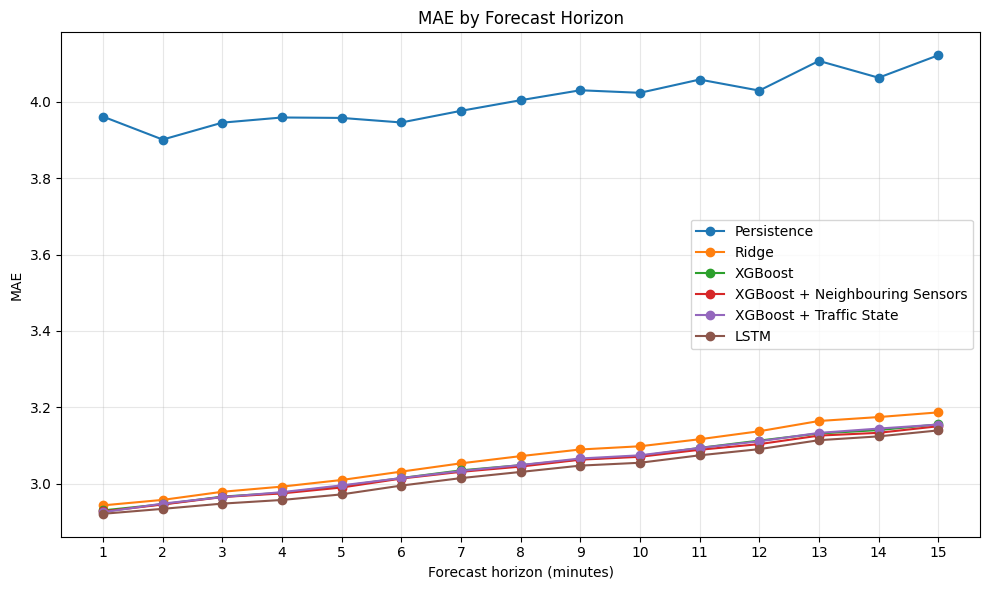

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    horizon_results["Horizon"],
    horizon_results["Persistence"],
    marker="o",
    label="Persistence")

plt.plot(
    horizon_results["Horizon"],
    horizon_results["Ridge"],
    marker="o",
    label="Ridge")

plt.plot(
    horizon_results["Horizon"],
    horizon_results["XGBoost"],
    marker="o",
    label="XGBoost")

plt.plot(
    horizon_results["Horizon"],
    horizon_results["XGBoost + Neighbouring Sensors"],
    marker="o",
    label="XGBoost + Neighbouring Sensors")

plt.plot(
    horizon_results["Horizon"],
    horizon_results["XGBoost + Traffic State"],
    marker="o",
    label="XGBoost + Traffic State")

plt.plot(
    horizon_results["Horizon"],
    horizon_results["LSTM"],
    marker="o",
    label="LSTM")

plt.xlabel("Forecast horizon (minutes)")
plt.ylabel("MAE")
plt.title("MAE by Forecast Horizon")
plt.xticks(range(1, 16))
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

Calculate XGBoost performance by sensor

Validation errors are calculated separately for each sensor using local XGBoost. All-horizon MAE ranges from approximately 1.4005 at sensor 4439 to 4.1850 at sensor 536. The number of complete forecasting examples varies substantially between sensors. Compare absolute metrics alongside MAPE, which can be high at low-flow locations, and avoid interpreting small-sample rankings as equally reliable.

In [ ]:
sensor_results = []

for sensor in sorted(df_val_model["DP_ID"].unique()):

    mask = df_val_model["DP_ID"].values == sensor

    y_true_sensor = y_val.values[mask]
    y_pred_sensor = y_pred_xgb[mask]

    mae = mean_absolute_error(
        y_true_sensor,
        y_pred_sensor)

    rmse = np.sqrt(
        mean_squared_error(
            y_true_sensor,
            y_pred_sensor))

    non_zero = y_true_sensor != 0

    mape = np.mean(
        np.abs(
            (y_true_sensor[non_zero] - y_pred_sensor[non_zero])
            / y_true_sensor[non_zero])) * 100

    sensor_results.append({
        "DP_ID": sensor,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "Observations": mask.sum()})

sensor_error_df = (
    pd.DataFrame(sensor_results)
    .sort_values("MAE")
    .reset_index(drop=True))

display(sensor_error_df)

,DP_ID,MAE,RMSE,MAPE,Observations
0,4439,1.400451,1.745326,61.036001,255
1,4496,1.634823,1.956898,83.392861,235
2,4495,1.870576,2.334381,56.565556,913
3,4872,1.894327,2.359328,63.710750,759
4,351,2.472311,3.147655,26.699059,1006
5,539,2.536245,3.181583,25.418665,1690
6,4873,2.613657,3.320035,43.192727,729
7,902,2.644447,3.329317,17.322947,1791
8,4473,2.678623,3.448533,25.966352,1772
9,1079,2.726383,3.423581,20.573776,1815


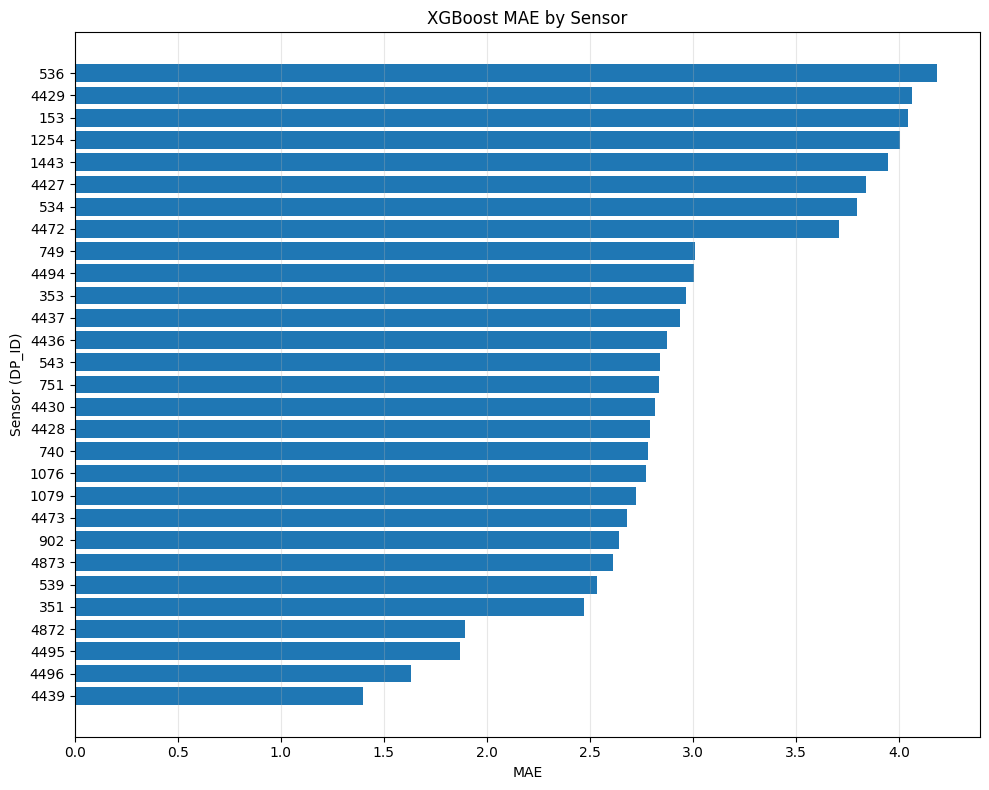

In [ ]:
import matplotlib.pyplot as plt

sensor_plot = sensor_error_df.sort_values("MAE", ascending=True)

plt.figure(figsize=(10, 8))

plt.barh(sensor_plot["DP_ID"].astype(str), sensor_plot["MAE"])

plt.xlabel("MAE")
plt.ylabel("Sensor (DP_ID)")
plt.title("XGBoost MAE by Sensor")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Checking the baseline LSTM validation performance before robustness testing

baseline_lstm_mae = mean_absolute_error(
    y_val_lstm,
    y_pred_lstm)

baseline_lstm_rmse = np.sqrt(
    mean_squared_error(
        y_val_lstm,
        y_pred_lstm))

print("Baseline LSTM performance")
print("-------------------------")
print(f"MAE:  {baseline_lstm_mae:.4f}")
print(f"RMSE: {baseline_lstm_rmse:.4f}")

Baseline LSTM performance
-------------------------
MAE:  3.0275
RMSE: 3.9128


In [ ]:
# Robustness test: 10% randomly missing input observations

import numpy as np

np.random.seed(42)

X_val_lstm_missing = X_val_lstm_scaled.copy()

# Randomly remove 10% of the input observations
missing_mask = np.random.rand(*X_val_lstm_missing.shape) < 0.10

X_val_lstm_missing[missing_mask] = np.nan

# Count missing values
print("Total input values:", X_val_lstm_missing.size)
print("Missing input values:", np.isnan(X_val_lstm_missing).sum())
print("Missing percentage:", np.isnan(X_val_lstm_missing).mean() * 100)

Total input values: 1283552
Missing input values: 128260
Missing percentage: 9.992583081947595


In [ ]:
# Handle missing observations using forward filling within each sequence

X_val_lstm_missing_filled = X_val_lstm_missing.copy()

for i in range(X_val_lstm_missing_filled.shape[0]):
    for feature in range(X_val_lstm_missing_filled.shape[2]):

        values = X_val_lstm_missing_filled[i, :, feature]

        # Training-mean fallback at the oldest step; then forward fill.
        if np.isnan(values[0]):
            values[0] = 0.0
        for t in range(1, len(values)):
            if np.isnan(values[t]):
                values[t] = values[t - 1]

print("Remaining missing values:", np.isnan(X_val_lstm_missing_filled).sum())

Remaining missing values: 0


In [ ]:
# Final fallback for sequences where all observations of a feature are missing
# 0 in standardized space corresponds to the training mean

X_val_lstm_missing_filled[
    np.isnan(X_val_lstm_missing_filled)] = 0

print("Remaining missing values:",
    np.isnan(X_val_lstm_missing_filled).sum())

Remaining missing values: 0


In [ ]:
# Predicting with 10% missing input observations

y_pred_lstm_missing = lstm_model.predict(
    X_val_lstm_missing_filled,
    verbose=1)

missing_mae = mean_absolute_error(
    y_val_lstm,
    y_pred_lstm_missing)

missing_rmse = np.sqrt(
    mean_squared_error(
        y_val_lstm,
        y_pred_lstm_missing))

print("LSTM with 10% missing input observations")
print("------------------------------------------")
print(f"MAE:  {missing_mae:.4f}")
print(f"RMSE: {missing_rmse:.4f}")

1254/1254 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step
LSTM with 10% missing input observations
------------------------------------------
MAE:  3.0426
RMSE: 3.9304


In [ ]:
def test_missing_data_robustness(
    X_input,
    y_true,
    model,
    missing_rate,
    seed=42):

    np.random.seed(seed)

    X_missing = X_input.copy()

    # Randomly remove input observations
    missing_mask = (np.random.rand(*X_missing.shape) < missing_rate)

    X_missing[missing_mask] = np.nan

    # Forward fill within each sequence
    for i in range(X_missing.shape[0]):
        for feature in range(X_missing.shape[2]):

            values = X_missing[i, :, feature]

            # Training-mean fallback at the oldest step; then forward fill.
            if np.isnan(values[0]):
                values[0] = 0.0
            for t in range(1, len(values)):
                if np.isnan(values[t]):
                    values[t] = values[t - 1]
    # Final fallback if an entire feature sequence is missing
    X_missing[np.isnan(X_missing)] = 0

    # Prediction
    y_pred = model.predict(X_missing, batch_size=256, verbose=0)
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred))

    return mae, rmse

In [ ]:
# Testing LSTM robustness at different missing-data levels

missing_rates = [0.05, 0.10, 0.20]

robustness_results = []

for rate in missing_rates:

    mae, rmse = test_missing_data_robustness(
        X_val_lstm_scaled,
        y_val_lstm,
        lstm_model,
        missing_rate=rate,
        seed=42)

    robustness_results.append({
        "Missing input": f"{int(rate * 100)}%",
        "MAE": mae,
        "RMSE": rmse})

# Adding the clean-data baseline
robustness_results.insert(0,
    {"Missing input": "0%",
        "MAE": baseline_lstm_mae,
        "RMSE": baseline_lstm_rmse})

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df)

,Missing input,MAE,RMSE
0,0%,3.027521,3.912750
1,5%,3.034847,3.921174
2,10%,3.042624,3.930384
3,20%,3.062746,3.954358


In [ ]:
# Creating a noisy version of the validation inputs

np.random.seed(42)

X_val_lstm_noisy = X_val_lstm_scaled.copy()

# Adding Gaussian noise with a standard deviation of 5%
noise = np.random.normal(
    loc=0,
    scale=0.05,
    size=X_val_lstm_noisy.shape)

X_val_lstm_noisy = X_val_lstm_noisy + noise

print("Original input shape: ", X_val_lstm_scaled.shape)
print("Noisy input shape: ", X_val_lstm_noisy.shape)
print("Noise standard deviation: ", noise.std())

Original input shape:  (40111, 16, 2)
Noisy input shape:  (40111, 16, 2)
Noise standard deviation:  0.050036688544615356


In [ ]:
# Predicting with noise at 5% of training SD

y_pred_lstm_noisy = lstm_model.predict(
    X_val_lstm_noisy, verbose=0)

noisy_mae = mean_absolute_error(
    y_val_lstm, y_pred_lstm_noisy)

noisy_rmse = np.sqrt(
    mean_squared_error(
        y_val_lstm,
        y_pred_lstm_noisy))

print("LSTM with 5% input noise")
print("------------------------")
print(f"MAE:  {noisy_mae:.4f}")
print(f"RMSE: {noisy_rmse:.4f}")

LSTM with 5% input noise
------------------------
MAE:  3.0282
RMSE: 3.9136


In [ ]:
# Testing LSTM robustness at different noise levels

noise_rates = [0.05, 0.10, 0.20]

noise_results = []

for rate in noise_rates:

    np.random.seed(42)

    # Creating noisy validation input
    X_noisy = X_val_lstm_scaled.copy()

    noise = np.random.normal(
        loc=0,
        scale=rate,
        size=X_noisy.shape)

    X_noisy = X_noisy + noise

    # Predicting
    y_pred_noisy = lstm_model.predict(
        X_noisy,
        verbose=0)

    # Evaluating
    mae = mean_absolute_error(
        y_val_lstm,
        y_pred_noisy)

    rmse = np.sqrt(
        mean_squared_error(
            y_val_lstm,
            y_pred_noisy))

    noise_results.append({
        "Noise level": f"{int(rate * 100)}%",
        "MAE": mae,
        "RMSE": rmse})

# Adding clean baseline
noise_results.insert(0, {
        "Noise level": "0%",
        "MAE": baseline_lstm_mae,
        "RMSE": baseline_lstm_rmse})

noise_df = pd.DataFrame(noise_results)

display(noise_df)

,Noise level,MAE,RMSE
0,0%,3.027521,3.912750
1,5%,3.028211,3.913591
2,10%,3.030299,3.915997
3,20%,3.038489,3.925530


C7. Model diagnostics and robustness

Several additional analyses are performed to understand the behaviour and limitations of the forecasting models.

First, prediction error is evaluated for each forecast horizon from 1 to 15 minutes. Model performance is also compared across individual sensors and traffic states.

The robustness of the LSTM model is tested by simulating random missing observations and noisy input measurements. These experiments are used to investigate how sensitive the model is to imperfect real-time sensor data.

Validation error is examined across horizons, sensors and traffic states. LSTM MAE increases from 2.9208 at t+1 to 3.1393 at t+15, showing that prediction becomes harder further ahead. Errors also vary between sensor locations and descriptive network states.

The LSTM's validation inputs are then perturbed with random missing values and Gaussian noise, while targets are kept unchanged and the model is not retrained. Missing values affect individual input entries. The tests use one random seed and operate on forecasting windows, so the same raw observation appearing in different windows need not receive an identical perturbation.

**Missing data result:** MAE changes from 3.0275 with clean inputs to 3.0348, 3.0426 and 3.0627 with 5%, 10% and 20% missing entries. RMSE changes from 3.9128 to 3.9212, 3.9304 and 3.9544. At 20% missingness, MAE rises by approximately 1.16%.

**Noise result:** MAE changes to 3.0282, 3.0303 and 3.0385 when Gaussian noise has SD equal to 5%, 10% and 20% of the training standard deviation. These percentages do not refer to each individual measurement's value. At the highest tested noise level, MAE rises by approximately 0.36%.

The model is relatively insensitive to these particular simulated perturbations. The results do not establish robustness to long sensor outages, systematic bias, asynchronous reporting or other untested real-time failures.

C8 — Final held-out evaluation

In [ ]:
# C8.1 — Finding and loading the 2022 evaluation dataset

import os
import pandas as pd

# Show CSV files in the Colab working directory
csv_files = [file for file in os.listdir()
    if file.lower().endswith(".csv")]

print("CSV files found:")
for file in csv_files:
    print("-", file)

CSV files found:
- evaluation_dataset.csv
- final_evaluation_dataset.csv
- training_dataset.csv


In [ ]:
# C8.1 — Loading the held-out evaluation dataset

df_test = pd.read_csv(str(Path("evaluation_dataset.csv") if Path("evaluation_dataset.csv").is_file() else Path("upload/evaluation_dataset.csv")), sep=";")

print("Evaluation dataset shape:", df_test.shape)
print("\nColumns:")
print(df_test.columns.tolist())

print("\nFirst rows:")
display(df_test.head())

print("\nDate range:")
print(df_test["Date"].min(), "to", df_test["Date"].max())

Evaluation dataset shape: (803377, 11)

Columns:
['DP_ID', 'PORTAL', 'Date', 'Time', 'Interval_1', 'Interval_5', 'Interval_15', 'Interval_30', 'Interval_60', 'SPEED_MS_AVG', 'FLOW']

First rows:


,DP_ID,PORTAL,Date,Time,Interval_1,Interval_5,Interval_15,Interval_30,Interval_60,SPEED_MS_AVG,FLOW
0,1254,"E4S 55,620",20220101,04:00:00,240,48,16,8,4,26.40,1.0
1,1443,"E4S 57,055",20220101,04:00:00,240,48,16,8,4,24.43,3.0
2,1079,"E4S 56,780",20220101,04:00:00,240,48,16,8,4,20.33,4.0
3,1076,"E4S 55,620",20220101,04:00:00,240,48,16,8,4,18.55,4.0
4,751,"E4S 55,620",20220101,04:00:00,240,48,16,8,4,22.19,7.0



Date range:
20220101 to 20220625


In [ ]:
# C8.1 — Preparing 2022 held-out test data

df_test = df_test.copy()

# Creating datetime
df_test["datetime"] = pd.to_datetime(
    df_test["Date"].astype(str) + " " + df_test["Time"].astype(str))

# Extracting time in minutes after midnight
df_test["time_minutes"] = (
    df_test["datetime"].dt.hour * 60
    + df_test["datetime"].dt.minute)

# Morning peak: 07:30–08:30
df_test_morning = df_test[
    (df_test["time_minutes"] >= 450) &
    (df_test["time_minutes"] <= 510)].copy()

print("2022 morning data shape:", df_test_morning.shape)
print("Date range:", df_test_morning["datetime"].min(), "to", df_test_morning["datetime"].max())
print("Number of sensors:", df_test_morning["DP_ID"].nunique())
print("Number of portals:", df_test_morning["PORTAL"].nunique())
print("Missing FLOW:", df_test_morning["FLOW"].isna().sum())
print("Missing SPEED:", df_test_morning["SPEED_MS_AVG"].isna().sum())

2022 morning data shape: (145354, 13)
Date range: 2022-01-01 07:30:00 to 2022-06-25 08:30:00
Number of sensors: 29
Number of portals: 8
Missing FLOW: 0
Missing SPEED: 0


## C8.2 — Create continuous sequences for the 2022 evaluation data


In [ ]:
# C8.2 — Creating continuous sequences for the 2022 evaluation data

df_test_morning_sorted = (
    df_test_morning
    .sort_values(["DP_ID", "datetime"])
    .copy())

# Calculating time gap between consecutive observations
df_test_morning_sorted["time_gap"] = (
    df_test_morning_sorted
    .groupby("DP_ID")["datetime"]
    .diff())

# Starting a new sequence whenever the gap is not exactly 1 minute
df_test_morning_sorted["sequence"] = (
    df_test_morning_sorted["time_gap"] != pd.Timedelta(minutes=1)).groupby(
    df_test_morning_sorted["DP_ID"]).cumsum()

print("Number of continuous sequences:",
      df_test_morning_sorted.groupby(
          ["DP_ID", "sequence"]).ngroups)

print("Longest sequence:",
    df_test_morning_sorted.groupby(
        ["DP_ID", "sequence"]).size().max())

print("Sequences with at least 31 observations:",
    (df_test_morning_sorted
        .groupby(["DP_ID", "sequence"])
        .size() >= 31).sum())

Number of continuous sequences: 6379
Longest sequence: 61
Sequences with at least 31 observations: 2090


### C8.3 — Create 2022 forecasting dataset


In [ ]:
# C8.3 — Creating 2022 forecasting dataset

# Creating all lags and targets BEFORE restricting prediction origins.
# Group by sensor AND sequence: sequence numbers repeat across sensors.
df_test_forecasting = df_test_morning_sorted.copy()

groups = df_test_forecasting.groupby(["DP_ID", "sequence"])
for lag in range(1, 16):
    df_test_forecasting[f"FLOW_t-{lag}"] = groups["FLOW"].shift(lag)
    df_test_forecasting[f"SPEED_t-{lag}"] = groups["SPEED_MS_AVG"].shift(lag)

for h in range(1, 16):
    df_test_forecasting[f"FLOW_t+{h}"] = groups["FLOW"].shift(-h)
df_test_forecasting = df_test_forecasting.loc[
    df_test_forecasting.time_minutes.between(450, 495)].copy()

print("Candidate 2022 origins:", len(df_test_forecasting))

Candidate 2022 origins: 109444


### C8.4 — Keep only complete 15-minute forecasting windows


In [ ]:
# C8.4 — Keeping only complete 15-minute forecasting windows

required_columns = feature_columns + target_columns

df_test_forecasting_clean = (
    df_test_forecasting
    .dropna(subset=required_columns)
    .copy())

print("Complete 2022 forecasting origins:",
      len(df_test_forecasting_clean))

print("Removed incomplete origins:",
    len(df_test_forecasting) - len(df_test_forecasting_clean))

print("Missing values in required columns:",
    df_test_forecasting_clean[required_columns].isna().sum().sum())

print("Prediction origin range:",
    df_test_forecasting_clean["datetime"].min(), "to", df_test_forecasting_clean["datetime"].max())

print("Sensors represented:",
    df_test_forecasting_clean["DP_ID"].nunique())

Complete 2022 forecasting origins: 59298
Removed incomplete origins: 50146
Missing values in required columns: 0
Prediction origin range: 2022-01-01 07:45:00 to 2022-06-25 08:15:00
Sensors represented: 29


### C8.5 — Create final 2022 test features and targets


In [ ]:
# C8.5 — Creating final 2022 test features and targets

X_test = df_test_forecasting_clean[feature_columns].copy()
y_test = df_test_forecasting_clean[target_columns].copy()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nMissing values in X_test:", X_test.isna().sum().sum())
print("Missing values in y_test:", y_test.isna().sum().sum())

print("\nExpected feature count:", len(feature_columns))
print("Expected target count:", len(target_columns))

X_test shape: (59298, 32)
y_test shape: (59298, 15)

Missing values in X_test: 0
Missing values in y_test: 0

Expected feature count: 32
Expected target count: 15


### C8.6 — Persistence baseline on 2022 held-out data


In [ ]:
# C8.6 — Persistence baseline on 2022 held-out data

# Current FLOW is the last feature in the FLOW sequence
y_pred_persistence_test = np.tile(
    X_test["FLOW"].values.reshape(-1, 1),
    (1, 15))

persistence_test_result = evaluate_model(
    y_test,
    y_pred_persistence_test,
    "Persistence — 2022 Test")

print("\n2022 test observations:", len(y_test))

Persistence — 2022 Test
-------------------------
MAE:  4.1846
RMSE: 5.4246
MAPE: 38.68%

2022 test observations: 59298


### C8.7 — Ridge Regression on 2022 held-out data


In [ ]:
# C8.7 — Ridge Regression on 2022 held-out data

# Apply the same scaler fitted on the training data
X_test_scaled = scaler.transform(X_test)

# Predict using the already trained Ridge model
y_pred_ridge_test = ridge_model.predict(X_test_scaled)

ridge_test_result = evaluate_model(
    y_test,
    y_pred_ridge_test,
    "Ridge Regression — 2022 Test")

Ridge Regression — 2022 Test
-------------------------
MAE:  3.2193
RMSE: 4.1592
MAPE: 33.12%


### C8.8 — XGBoost on 2022 held-out data


In [ ]:
# C8.8 — XGBoost on 2022 held-out data

y_pred_xgb_test = xgb_model.predict(X_test)

xgb_test_result = evaluate_model(
    y_test,
    y_pred_xgb_test,
    "XGBoost — 2022 Test")

XGBoost — 2022 Test
-------------------------
MAE:  3.1993
RMSE: 4.1294
MAPE: 32.57%


C8.9 — Prepare the 2022 data for LSTM

In [ ]:
# Checking the LSTM-related variables currently available

lstm_variables = [
    "X_train_lstm_scaled",
    "X_val_lstm_scaled",
    "y_train_lstm",
    "y_val_lstm",
    "X_train_lstm",
    "X_val_lstm"]

for var in lstm_variables:
    print(f"{var}: {'available' if var in globals() else 'NOT available'}")

X_train_lstm_scaled: available
X_val_lstm_scaled: available
y_train_lstm: available
y_val_lstm: available
X_train_lstm: available
X_val_lstm: available


In [ ]:
# Finding scaler variables currently available

scaler_variables = {
    name: type(value).__name__
    for name, value in globals().items()
    if "scaler" in name.lower()}

scaler_variables

{'StandardScaler': 'type',
 'lstm_scaler': 'StandardScaler',
 'scaler': 'StandardScaler',
 'selection_scaler': 'StandardScaler',
 'state_scaler': 'StandardScaler'}

In [ ]:
print("LSTM scaler type:", type(lstm_scaler).__name__)
print("Number of features:", lstm_scaler.n_features_in_)
print("Scaler mean shape:", lstm_scaler.mean_.shape)

LSTM scaler type: StandardScaler
Number of features: 2
Scaler mean shape: (2,)


### C8.9 — Prepare 2022 data for LSTM

In [ ]:
# C8.9 — Preparing 2022 data for LSTM

X_test_lstm, y_test_lstm = create_sequences(df_test_forecasting_clean)

print("Raw X_test_lstm shape:", X_test_lstm.shape)
print("Raw y_test_lstm shape:", y_test_lstm.shape)

# Scale FLOW and SPEED using the scaler fitted on the training data
X_test_lstm_scaled = lstm_scaler.transform(
    X_test_lstm.reshape(-1, 2)).reshape(X_test_lstm.shape)

print("Scaled X_test_lstm shape:", X_test_lstm_scaled.shape)
print("Missing values:", np.isnan(X_test_lstm_scaled).sum())

Raw X_test_lstm shape: (59298, 16, 2)
Raw y_test_lstm shape: (59298, 15)
Scaled X_test_lstm shape: (59298, 16, 2)
Missing values: 0


C8.10 — LSTM on 2022 held-out data

In [ ]:
# C8.10 — LSTM on 2022 held-out data

y_pred_lstm_test = lstm_model.predict(
    X_test_lstm_scaled,
    verbose=1)

lstm_test_result = evaluate_model(
    y_test_lstm,
    y_pred_lstm_test,
    "LSTM — 2022 Test")

1854/1854 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step
LSTM — 2022 Test
-------------------------
MAE:  3.1948
RMSE: 4.1250
MAPE: 31.46%


### C8.11 — LSTM error by forecast horizon


In [ ]:
# C8.11 — LSTM error by forecast horizon

lstm_test_horizon_mae = horizon_mae(y_test_lstm, y_pred_lstm_test)

for h, mae in enumerate(lstm_test_horizon_mae, start=1):
    print(f"{h:2d} min ahead: MAE = {mae:.4f}")

 1 min ahead: MAE = 3.0839
 2 min ahead: MAE = 3.0965
 3 min ahead: MAE = 3.1101
 4 min ahead: MAE = 3.1173
 5 min ahead: MAE = 3.1320
 6 min ahead: MAE = 3.1605
 7 min ahead: MAE = 3.1788
 8 min ahead: MAE = 3.1910
 9 min ahead: MAE = 3.2087
10 min ahead: MAE = 3.2242
11 min ahead: MAE = 3.2491
12 min ahead: MAE = 3.2567
13 min ahead: MAE = 3.2865
14 min ahead: MAE = 3.3062
15 min ahead: MAE = 3.3203


### C8.12 — Final 2022 held-out test comparison


In [ ]:
# C8.12 — Final 2022 held-out test comparison

final_test_results = pd.DataFrame([
    persistence_test_result,
    ridge_test_result,
    xgb_test_result,
    lstm_test_result])

# Calculating improvement relative to persistence
baseline_mae = final_test_results.loc[
    final_test_results["Model"] == "Persistence — 2022 Test",
    "MAE"].iloc[0]

baseline_rmse = final_test_results.loc[
    final_test_results["Model"] == "Persistence — 2022 Test",
    "RMSE"].iloc[0]

baseline_mape = final_test_results.loc[
    final_test_results["Model"] == "Persistence — 2022 Test",
    "MAPE"].iloc[0]

final_test_results["MAE improvement vs persistence (%)"] = (
    (baseline_mae - final_test_results["MAE"])
    / baseline_mae * 100)

final_test_results["RMSE improvement vs persistence (%)"] = (
    (baseline_rmse - final_test_results["RMSE"])
    / baseline_rmse * 100)

final_test_results["MAPE improvement vs persistence (%)"] = (
    (baseline_mape - final_test_results["MAPE"])
    / baseline_mape * 100)

# Sort by MAE
final_test_results = final_test_results.sort_values(
    "MAE").reset_index(drop=True)

display(final_test_results.round(4))

,Model,MAE,RMSE,MAPE,MAE improvement vs persistence (%),RMSE improvement vs persistence (%),MAPE improvement vs persistence (%)
0,LSTM — 2022 Test,3.1948,4.1250,31.4629,23.6538,23.9581,18.6498
1,XGBoost — 2022 Test,3.1993,4.1294,32.5745,23.5470,23.8768,15.7758
2,Ridge Regression — 2022 Test,3.2193,4.1592,33.1182,23.0686,23.3272,14.3698
3,Persistence — 2022 Test,4.1846,5.4246,38.6759,0.0000,0.0000,0.0000


C8. Final held-out evaluation

After model development and validation, the models are evaluated on an untouched 2022 dataset. This dataset is kept separate from the training and validation stages and is therefore used as the final test of generalisation to unseen data.

There are 59,298 complete forecasting origins, covering 07:45–08:15 across 29 sensors. Lags and targets are constructed before origin filtering, retaining the later minutes required for late origin targets.

The same input structure and evaluation metrics are used as in the validation stage. The persistence model, Ridge Regression, XGBoost and LSTM are compared using MAE, RMSE and MAPE.

This file is the first external evaluation and has been inspected during the project. The separate final_evaluation_dataset.csv is assessed in D6; the two files contain different days within the same January–June period rather than sequential future periods.

**Result:** The LSTM achieved all-horizon MAE 3.1948, RMSE 4.1250 and MAPE 31.46%. XGBoost achieved 3.1993, 4.1294 and 32.57%; Ridge achieved 3.2193, 4.1592 and 33.12%; persistence achieved 4.1846, 5.4246 and 38.68%. LSTM was best on these aggregate metrics, but its absolute-error advantage over XGBoost was small. These averages are not the separate t+15 endpoint.

C9 — Model selection and deployment recommendation

C9.1 — Compare validation vs. final 2022 performance

The table compares validation with the first 2022 evaluation file. LSTM all-horizon MAE increases from 3.0275 to 3.1948, while XGBoost increases from 3.0451 to 3.1993. The learned models continue to outperform persistence, but performance changes across periods. This supports temporal transfer on the represented sensor network, not generalisation to unseen sensors or other roads. The separate final-file endpoint is reported in D6.

In [ ]:
# C9.1 — Validation vs. final 2022 test performance
# Compute results from actual predictions; no hard-coded stale metrics.
validation_results = pd.DataFrame([
    evaluate_model(y_val, pred, name)
    for name, pred in [("Persistence", y_pred_persistence), ("Ridge Regression", y_pred_ridge),
                       ("XGBoost", y_pred_xgb), ("LSTM", y_pred_lstm)]
]).rename(columns={"MAE":"Validation MAE", "RMSE":"Validation RMSE", "MAPE":"Validation MAPE"})
test_results_c9 = final_test_results[["Model", "MAE", "RMSE", "MAPE"]].copy()
test_results_c9["Model"] = test_results_c9.Model.str.replace(" — 2022 Test", "", regex=False)
test_results_c9 = test_results_c9.rename(columns={"MAE":"2022 Test MAE", "RMSE":"2022 Test RMSE", "MAPE":"2022 Test MAPE"})
comparison_c9 = validation_results.merge(test_results_c9, on="Model", validate="one_to_one")
display(comparison_c9)

Persistence
-------------------------
MAE:  4.0060
RMSE: 5.1895
MAPE: 36.44%
Ridge Regression
-------------------------
MAE:  3.0668
RMSE: 3.9703
MAPE: 31.02%
XGBoost
-------------------------
MAE:  3.0451
RMSE: 3.9286
MAPE: 30.02%
LSTM
-------------------------
MAE:  3.0275
RMSE: 3.9128
MAPE: 29.00%


,Model,Validation MAE,Validation RMSE,Validation MAPE,2022 Test MAE,2022 Test RMSE,2022 Test MAPE
0,Persistence,4.006027,5.189521,36.437934,4.184604,5.424598,38.675904
1,Ridge Regression,3.066771,3.970300,31.021027,3.219276,4.159190,33.118237
2,XGBoost,3.045095,3.928628,30.022425,3.199258,4.129378,32.574476
3,LSTM,3.027521,3.912750,29.000881,3.194785,4.124966,31.462942


C9.2 — Quantify the LSTM vs XGBoost advantage

On the first 2022 evaluation file, LSTM reduces all-horizon MAE by approximately 0.14%, RMSE by 0.11% and MAPE by 3.41% relative to XGBoost. The absolute-error differences are very small. Model complexity, inference cost and maintainability should therefore accompany the accuracy comparison when considering deployment.

In [ ]:
# C9.2 — LSTM vs. XGBoost on the final 2022 test set

lstm_mae = final_test_results.loc[
    final_test_results["Model"] == "LSTM — 2022 Test",
    "MAE"].iloc[0]

xgb_mae = final_test_results.loc[
    final_test_results["Model"] == "XGBoost — 2022 Test",
    "MAE"].iloc[0]

lstm_rmse = final_test_results.loc[
    final_test_results["Model"] == "LSTM — 2022 Test",
    "RMSE"].iloc[0]

xgb_rmse = final_test_results.loc[
    final_test_results["Model"] == "XGBoost — 2022 Test",
    "RMSE"].iloc[0]

lstm_mape = final_test_results.loc[
    final_test_results["Model"] == "LSTM — 2022 Test",
    "MAPE"].iloc[0]

xgb_mape = final_test_results.loc[
    final_test_results["Model"] == "XGBoost — 2022 Test",
    "MAPE"].iloc[0]

print("LSTM vs XGBoost — 2022 Test")
print("----------------------------")

print(f"MAE improvement: "
    f"{(xgb_mae - lstm_mae) / xgb_mae * 100:.2f}%")

print(f"RMSE improvement: "
    f"{(xgb_rmse - lstm_rmse) / xgb_rmse * 100:.2f}%")

print(f"MAPE improvement: "
    f"{(xgb_mape - lstm_mape) / xgb_mape * 100:.2f}%")

LSTM vs XGBoost — 2022 Test
----------------------------
MAE improvement: 0.14%
RMSE improvement: 0.11%
MAPE improvement: 3.41%


C9.3 — Final deployment recommendation

LSTM is the selected local model because it has the lowest validation MAE at exactly t+15 (3.1393). The 2022 files provide subsequent evaluation rather than a basis for choosing or tuning the model.

On the separate final file, LSTM achieves MAE15 3.2016, RMSE15 4.1286 and nonzero-target MAPE15 29.39%. Local XGBoost achieves MAE15 3.2099, so the models remain close. A supervised shadow-mode pilot is more appropriate than immediate autonomous control. XGBoost is a practical alternative where its implementation cost or maintainability is preferable, but those operational differences should be measured rather than assumed.

The robustness evidence is limited to the simulated validation-input failures. Real-time availability, FLOW units, measurement delay, latency and acceptable error thresholds must be established with the agency before operational use.

# Task D Model diagnostics

## D1. Overall model performance

The LSTM's overall performance on the first 2022 evaluation file provides a reference for the diagnostics. Across all fifteen horizons, MAE is 3.1948, RMSE is 4.1250 and MAPE is 31.46%.

At exactly t+15, MAE is approximately 3.3203. The separate final-file results in D6 are calculated on a different cohort and should be labelled separately.

## D2. Performance across forecast horizons

To investigate when the model becomes less accurate, the LSTM prediction error is evaluated separately for each forecast horizon from 1 to 15 minutes ahead.

The results show a general increase in MAE as the forecast horizon becomes longer. MAE increases from approximately 3.0839 at t+1 to 3.3203 at t+15. This analysis describes how prediction error changes as the target moves further from the origin, rather than averaging over all future minutes.

In [ ]:
print([name for name in globals() if "horizon" in name.lower()])

['horizon', 'horizon_mae', 'horizon_results', 'neighbor_horizon_mae', 'lstm_test_horizon_mae']


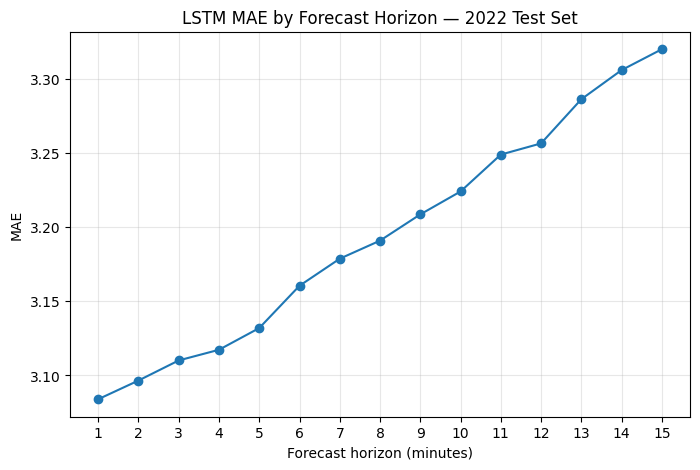

In [ ]:
import matplotlib.pyplot as plt

horizons = range(1, 16)

plt.figure(figsize=(8, 5))
plt.plot(
    horizons,
    lstm_test_horizon_mae,
    marker="o")

plt.xlabel("Forecast horizon (minutes)")
plt.ylabel("MAE")
plt.title("LSTM MAE by Forecast Horizon — 2022 Test Set")
plt.xticks(horizons)
plt.grid(True, alpha=0.3)

plt.show()

### Interpretation

The increasing horizon-error curve indicates lower accuracy further ahead. The difference between t+1 and t+15 is approximately 0.2364 FLOW units, or 7.66% of the t+1 MAE. The increase is gradual in this run, but it does not guarantee comparable performance beyond fifteen minutes or during unobserved conditions.

In [ ]:
print([name for name in globals() if "sensor" in name.lower()])

['sensor', 'sensor_df', 'sensor_flow', 'sensor_speed', 'morning_sensor_flow', 'morning_sensor_speed', 'sensor_portal', 'observations_per_sensor', 'sensor_ranges', 'sensor_times', 'sensor_mapping', 'sensor_results', 'y_true_sensor', 'y_pred_sensor', 'sensor_error_df', 'sensor_plot']


## D3. Performance across sensors

The LSTM is evaluated separately at each sensor on the first 2022 evaluation file. MAE, RMSE and MAPE are averaged over all fifteen horizons within each sensor. Observation counts are reported because the sensors do not have equal numbers of complete examples. These sensor-level averages differ from the t+15 diagnostics in D5 and D6.

MAE, RMSE and MAPE are calculated for each sensor using the held-out 2022 evaluation dataset.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Sensor ID for each prediction origin
sensor_ids = df_test_forecasting_clean["DP_ID"].values

sensor_results_lstm = []

for sensor_id in sorted(np.unique(sensor_ids)):
    mask = sensor_ids == sensor_id

    y_true_sensor = y_test.values[mask]
    y_pred_sensor = y_pred_lstm_test[mask]

    mae = mean_absolute_error(y_true_sensor, y_pred_sensor)
    rmse = np.sqrt(mean_squared_error(y_true_sensor, y_pred_sensor))

    non_zero = y_true_sensor != 0
    mape = np.mean(
        np.abs(
            (y_true_sensor[non_zero] - y_pred_sensor[non_zero])
            / y_true_sensor[non_zero])) * 100

    sensor_results_lstm.append({
        "DP_ID": sensor_id,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "Observations": mask.sum()})

sensor_results_lstm = pd.DataFrame(sensor_results_lstm)

sensor_results_lstm = sensor_results_lstm.sort_values(
    "MAE").reset_index(drop=True)

sensor_results_lstm

,DP_ID,MAE,RMSE,MAPE,Observations
0,4496,1.418346,1.743909,67.001141,243
1,4439,1.519277,1.987119,58.598230,418
2,4495,1.817191,2.303468,52.082566,1209
3,4872,1.955836,2.481542,59.484732,1046
4,4873,2.652856,3.326494,38.790532,1729
5,4428,2.735417,3.495251,22.752689,2160
6,4494,2.736419,3.524629,31.473910,2396
7,4473,2.758136,3.494319,23.626723,2436
8,4430,2.839572,3.611402,20.635928,2369
9,539,2.843096,3.632046,28.777276,2484


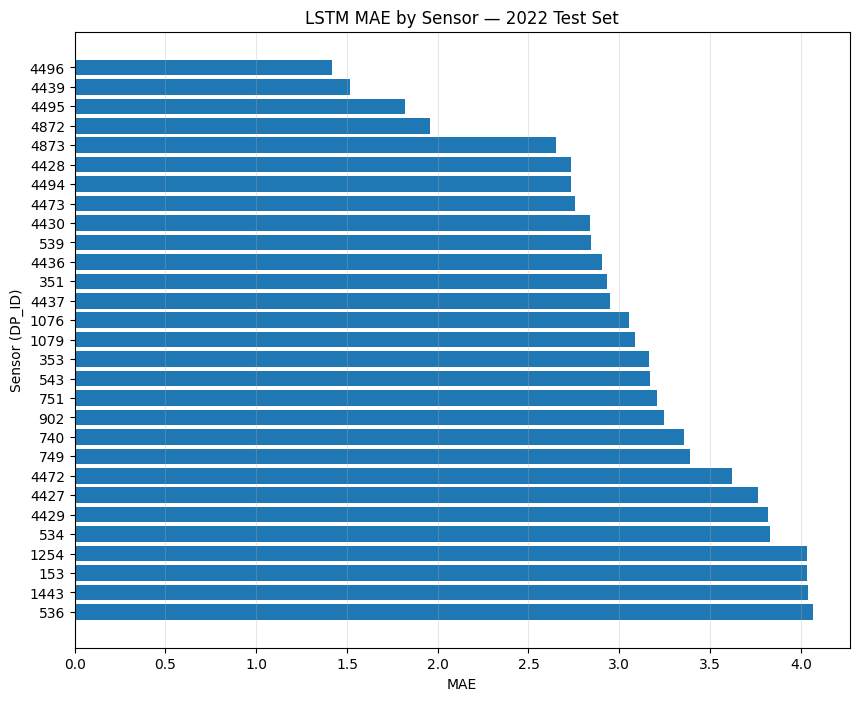

In [ ]:
plt.figure(figsize=(10, 8))

plt.barh(
    sensor_results_lstm["DP_ID"].astype(str),
    sensor_results_lstm["MAE"])

plt.xlabel("MAE")
plt.ylabel("Sensor (DP_ID)")
plt.title("LSTM MAE by Sensor — 2022 Test Set")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.show()

### Interpretation

All-horizon LSTM MAE ranges from 1.4183 at sensor 4496 to 4.0660 at sensor 536. Sensor 4496 contributes only 243 complete origins, whereas sensor 536 contributes 2,133. The ranking therefore reflects both local conditions and different evaluated samples.

Low absolute error can coexist with high MAPE. For example, sensor 4496 has MAPE approximately 67.00% despite its low MAE, consistent with percentage errors becoming large at small actual flows. Absolute metrics and observation counts should accompany percentage-based comparisons.

## D4. Performance across traffic states

To investigate whether traffic conditions affect prediction accuracy, the LSTM is evaluated separately for the different traffic states identified during the clustering analysis.

LSTM errors on the first 2022 evaluation file are grouped by the training-fitted network state assigned at each prediction origin. State features are computed from current raw sensor measurements rather than future-complete forecasting rows. The scaler and K-means model are reused without refitting.

This examines differences in prediction difficulty across descriptive traffic patterns; it does not itself show that adding state features improves the model.

In [ ]:
print([name for name in globals() if "state" in name.lower()])

['state_data', 'traffic_state_features', 'state_features', 'state_scaler', 'kmeans_state', 'state_summary', 'traffic_state_train', 'traffic_state_val', 'X_state_train', 'X_state_val', 'X_state_train_scaled', 'X_state_val_scaled', 'state_labels_train', 'state_labels_val', 'df_train_state', 'df_val_state', 'X_train_state', 'X_val_state', 'state_train_dummies', 'state_val_dummies', 'y_train_state', 'y_val_state', 'xgb_state_base', 'xgb_state_model', 'y_pred_xgb_state', 'xgb_state_result', 'state_error_results', 'state', 'y_true_state', 'y_pred_state', 'state_error_df']


In [ ]:
# Creating traffic-state features for the 2022 test data
test_state_features = (
    df_test_forecasting_clean
    .groupby("datetime")
    .agg(
        mean_flow=("FLOW", "mean"),
        std_flow=("FLOW", "std"),
        mean_speed=("SPEED_MS_AVG", "mean"),
        std_speed=("SPEED_MS_AVG", "std"))
    .reset_index())

# Matching the feature order used when training the clustering model
state_feature_columns = [
    "mean_flow",
    "std_flow",
    "mean_speed",
    "std_speed"]

# Removing timestamps with incomplete state information
test_state_features = test_state_features.dropna(
    subset=state_feature_columns).reset_index(drop=True)

# Applying the training scaler to the 2022 data
X_test_state_scaled = state_scaler.transform(
    test_state_features[state_feature_columns])

# Assigning traffic states using the training-fitted K-means model
test_state_features["state"] = kmeans_state.predict(X_test_state_scaled)

# Showing the resulting traffic states
test_state_features.head()

,datetime,mean_flow,std_flow,mean_speed,std_speed,state
0,2022-01-01 07:45:00,4.00,1.414214,21.3800,0.893420,1
1,2022-01-01 07:46:00,5.25,0.957427,21.6300,0.323213,1
2,2022-01-01 07:47:00,2.50,0.577350,24.5525,2.451345,1
3,2022-01-01 07:48:00,2.75,0.500000,22.7900,2.585305,1
4,2022-01-01 07:49:00,3.75,0.500000,22.1975,1.655665,1


In [ ]:
# Matchig each LSTM prediction to its network-level traffic state

test_datetimes = df_test_forecasting_clean["datetime"].values

# Creating a lookup from datetime to traffic state
state_lookup = test_state_features.set_index("datetime")["state"]

# Assigning the state to every prediction origin
test_prediction_states = pd.Series(
    pd.to_datetime(test_datetimes)).map(state_lookup)

# Checking that every prediction has a traffic state
print("Missing state assignments:", test_prediction_states.isna().sum())

# Calculating LSTM performance for each traffic state
state_results_lstm = []

for traffic_state in sorted(test_prediction_states.dropna().unique()):
    mask = test_prediction_states.values == traffic_state

    y_true_state = y_test.values[mask]
    y_pred_state = y_pred_lstm_test[mask]

    mae = mean_absolute_error(y_true_state, y_pred_state)
    rmse = np.sqrt(mean_squared_error(y_true_state, y_pred_state))

    non_zero = y_true_state != 0
    mape = np.mean(
        np.abs(
            (y_true_state[non_zero] - y_pred_state[non_zero])
            / y_true_state[non_zero])) * 100

    state_results_lstm.append({
        "Traffic State": int(traffic_state),
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "Observations": mask.sum()})

state_results_lstm = pd.DataFrame(state_results_lstm)

state_results_lstm

Missing state assignments: 0


,Traffic State,MAE,RMSE,MAPE,Observations
0,0,3.764873,4.836462,29.492381,4217
1,1,2.775949,3.588371,35.764079,18273
2,2,3.337399,4.282476,29.553444,36808


Interpretation

The LSTM performance varies across the three traffic states. State 0 has the highest all-horizon MAE (3.7649) and RMSE (4.8365); State 1 has the lowest (2.7759 and 3.5884); State 2 is intermediate (3.3374 and 4.2825). State 0's training profile has lower mean speed and more speed variation, providing a descriptive association with harder prediction rather than proof of physical congestion.

MAPE is highest in State 1 (35.76%), despite its lower absolute errors; State 0 and State 2 have approximately 29.49% and 29.55%. This illustrates why percentage-based error and absolute error can produce different rankings. Report the state characteristics and sample counts alongside the errors.

## D5. missing diagnostics and generalisation

Additional LSTM diagnostics on the first 2022 evaluation file examine month, origin time, sensor and residual patterns. Positive residuals indicate overprediction; negative residuals indicate underprediction.

Monthly MAE15 is 3.0581 in January, 3.3190 in February, 3.3671 in March, 3.3868 in April, 3.3611 in May and 3.4784 in June. The later months show larger errors than January, although the pattern is not strictly monotonic. Mean t+15 bias changes from +0.2005 in January to −0.9558 in June, indicating greater average underprediction in June. Changes in traffic and evaluated sample composition are possible explanations, not established causes.

By origin time, MAE15 ranges from approximately 3.1500 at 07:52 to 3.5034 at 08:03. Average residuals tend to be positive for earlier origins and negative later in the window. The residual plots and one-day sensor example help show errors that aggregate metrics can hide.

These analyses describe temporal transfer within the represented network. They do not establish generalisation to unseen sensor locations, future years or other road systems.

,N,MAE_all,MAE15,Bias15,RMSE15
month_eval,,,,,
2022-01,10879,2.997089,3.058125,0.200462,3.917718
2022-02,7334,3.174760,3.318981,-0.115765,4.360286
2022-03,12083,3.164234,3.367105,0.242457,4.488131
2022-04,9771,3.267095,3.386831,-0.152996,4.342472
2022-05,11905,3.291529,3.361101,-0.294435,4.283401
2022-06,7326,3.305141,3.478443,-0.955751,4.460103


,N,MAE_all,MAE15,Bias15,RMSE15
origin_time,,,,,
07:45,1920,3.231860,3.436867,0.831132,4.451023
07:46,1930,3.237453,3.489568,0.812216,4.535355
07:47,1924,3.225528,3.235915,0.854570,4.209364
07:48,1924,3.222151,3.377795,0.870606,4.359846
07:49,1924,3.217324,3.289194,0.874065,4.280344
07:50,1914,3.211717,3.405306,0.831738,4.486920
07:51,1923,3.206697,3.331548,0.460270,4.353010
07:52,1923,3.182058,3.150021,0.264988,4.136880
07:53,1915,3.182023,3.224840,0.362805,4.259592


,N,MAE_all,MAE15,Bias15,RMSE15
DP_ID,,,,,
153,2171,4.036930,4.274844,0.582622,5.410849
351,2292,2.933209,3.042571,0.087691,3.902590
353,2410,3.163029,3.205318,-0.136913,4.054222
534,1966,3.830550,4.126411,0.992088,5.224741
536,2133,4.066034,4.413111,0.700850,5.585225
539,2484,2.843096,2.894887,-0.227323,3.711026
543,2462,3.171164,3.252947,-0.140767,4.239227
740,2614,3.355419,3.494184,-1.400741,4.499030
749,2610,3.388414,3.487112,-1.449929,4.436181


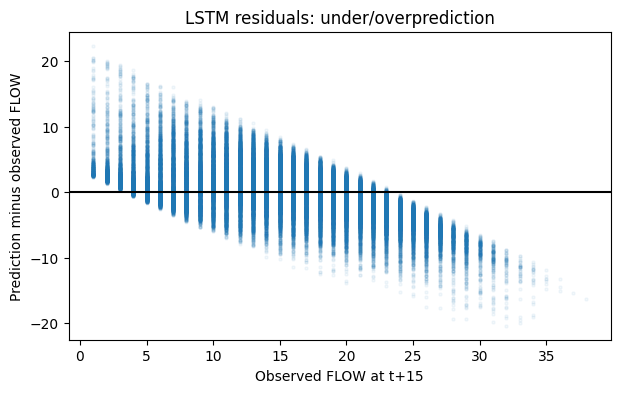

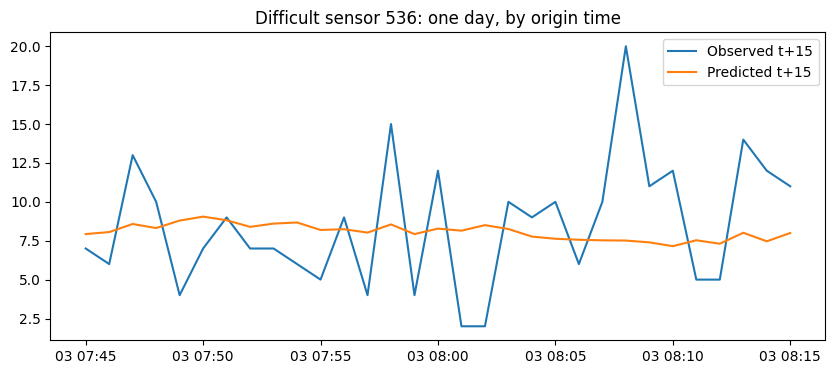

In [ ]:
test_meta = df_test_forecasting_clean.reset_index(drop=True).copy()
assert len(test_meta) == len(y_pred_lstm_test) == len(y_test)
assert np.allclose(test_meta[target_columns].to_numpy(), y_test.to_numpy())

test_meta["month_eval"] = test_meta.datetime.dt.to_period("M").astype(str)

test_meta["origin_time"] = test_meta.datetime.dt.strftime("%H:%M")
err = y_pred_lstm_test - y_test.to_numpy()

test_meta["abs_error_all"] = np.abs(err).mean(axis=1)

test_meta["abs_error15"] = np.abs(err[:, -1])

test_meta["squared_error15"] = err[:, -1]**2

test_meta["bias15"] = err[:, -1]

for key in ["month_eval", "origin_time", "DP_ID"]:
    table = test_meta.groupby(key).agg(N=("abs_error15","size"),
        MAE_all=("abs_error_all","mean"), MAE15=("abs_error15","mean"),
        MSE15=("squared_error15","mean"), Bias15=("bias15","mean"))
    table["RMSE15"] = np.sqrt(table.pop("MSE15"))
    display(table)

plt.figure(figsize=(7,4))
plt.scatter(y_test.to_numpy()[:, -1], err[:, -1], alpha=.05, s=5)
plt.axhline(0, color="black")
plt.xlabel("Observed FLOW at t+15"); plt.ylabel("Prediction minus observed FLOW")
plt.title("LSTM residuals: under/overprediction"); plt.show()


# One full day for a difficult sensor: avoid joining across dates.
worst = test_meta.groupby("DP_ID").abs_error15.mean().idxmax()

example = test_meta.loc[test_meta.DP_ID == worst].copy()

example = example.loc[example.datetime.dt.normalize() == example.datetime.dt.normalize().min()]

plt.figure(figsize=(10,4))
plt.plot(example.datetime, y_test.to_numpy()[example.index, -1], label="Observed t+15")
plt.plot(example.datetime, y_pred_lstm_test[example.index, -1], label="Predicted t+15")
plt.legend(); plt.title(f"Difficult sensor {worst}: one day, by origin time"); plt.show()

## D6. Separate final evaluation

final_evaluation_dataset.csv contains days that do not overlap with the first 2022 evaluation file, although both cover the same January–June period and sensor network. The local model is selected using 2021 validation MAE15 before final-file prediction errors are examined. The models and cluster/preprocessing parameters are reused without refitting.

This construction retains observations from 07:15–08:30 before selecting origins, producing 88,437 complete examples across 29 sensors with origins 07:30–08:15. Training, validation and the first evaluation in this saved notebook instead begin at 07:45. The wider final origin window is a methodological difference and should be reported when comparing metrics between files.

**Local-model result:** MAE15 is 4.2815 for persistence, 3.2473 for Ridge, 3.2099 for XGBoost and 3.2016 for LSTM. LSTM's RMSE15 is 4.1286 and nonzero-target MAPE15 is 29.39%. LSTM was selected on validation, not because of this final ranking.

**Feature-ablation result:** Single-target XGBoost MAE15 is 3.2099 with local features, 3.2025 with neighbours, 3.2065 with states, 3.1994 with both and 3.2085 with raw network statistics. All variants are compared on the same final rows. The neighbour-only and state-only reductions are approximately 0.23% and 0.11% respectively; the combined variant reduces MAE by approximately 0.33%. These changes are small.

**Main research question:** Adding states produces MAE15 gain 0.0035, with a 95% day-bootstrap interval [−0.0012, 0.0074]. Because the interval includes zero, a clear forecasting improvement through clustering is not established in this run. The states can still describe network patterns and support diagnostics without improving forecast accuracy reliably.

**Final diagnostics:** LSTM MAE15 is approximately 2.8082 in January and 3.3404 in June, with intermediate monthly differences. Sensor and state tables show where accuracy varies. These results support a cautious assessment of transfer across dates on the same network rather than a claim of universal real-time performance.

In [ ]:
# D6. Separate final evaluation with the same 07:15–08:30 construction.
local_validation_predictions = {"Persistence": y_pred_persistence, "Ridge": y_pred_ridge,
                                "XGBoost": y_pred_xgb, "LSTM": y_pred_lstm}

validation15 = pd.DataFrame([{"Model": name, **metrics15(y_val.to_numpy()[:, -1], pred[:, -1])}
                             for name, pred in local_validation_predictions.items()])

selected_local_model = validation15.sort_values("MAE15").iloc[0]["Model"]

print("Local model selected on validation t+15:", selected_local_model)
display(validation15)

final_path = Path("final_evaluation_dataset.csv")
if not final_path.is_file(): final_path = Path("upload/final_evaluation_dataset.csv")
if not final_path.is_file():
    from google.colab import files
    files.upload()
    final_path = Path("final_evaluation_dataset.csv")

final_raw = pd.read_csv(final_path, sep=";")

final_raw["datetime"] = pd.to_datetime(final_raw.Date.astype(str)+" "+final_raw.Time, format="%Y%m%d %H:%M:%S")

final_raw["time_minutes"] = final_raw.datetime.dt.hour*60+final_raw.datetime.dt.minute
assert set(final_raw.datetime.dt.normalize()).isdisjoint(set(df_test.datetime.dt.normalize()))

final_buffer = final_raw.loc[final_raw.time_minutes.between(435,510)].sort_values(["DP_ID","datetime"]).copy()

gaps = final_buffer.groupby("DP_ID").datetime.diff()

final_buffer["sequence"] = gaps.ne(pd.Timedelta(minutes=1)).groupby(final_buffer.DP_ID).cumsum()

groups = final_buffer.groupby(["DP_ID","sequence"])
for lag in range(1,16):
    final_buffer[f"FLOW_t-{lag}"] = groups.FLOW.shift(lag)
    final_buffer[f"SPEED_t-{lag}"] = groups.SPEED_MS_AVG.shift(lag)
for horizon in range(1,16): final_buffer[f"FLOW_t+{horizon}"] = groups.FLOW.shift(-horizon)

final_origins = final_buffer.loc[final_buffer.time_minutes.between(450,495)].dropna(subset=feature_columns+target_columns).reset_index(drop=True)
print("Final origins:",len(final_origins),"sensors:",final_origins.DP_ID.nunique())

final_y = final_origins[target_columns].to_numpy()

final_x = final_origins[feature_columns]

final_seq, _ = create_sequences(final_origins)

final_scaled = lstm_scaler.transform(final_seq.reshape(-1,2)).reshape(final_seq.shape)

final_predictions = {
    "Persistence": np.repeat(
        final_origins.FLOW.to_numpy()[:, None], 15, axis=1),
    "Ridge": ridge_model.predict(scaler.transform(final_x)),
    "XGBoost": xgb_model.predict(final_x),
    "LSTM": lstm_model.predict(
        final_scaled, batch_size=256, verbose=0)}

final_endpoint_results = pd.DataFrame([
    {"Model": name,
        **metrics15(final_y[:, -1], pred[:, -1])}
    for name, pred in final_predictions.items()])

display(final_endpoint_results)


# States computed from current raw observations, never from future-complete rows.
final_network = final_raw.loc[final_raw.time_minutes.between(450,510)].groupby("datetime").agg(
    mean_flow=("FLOW","mean"),std_flow=("FLOW","std"),mean_speed=("SPEED_MS_AVG","mean"),std_speed=("SPEED_MS_AVG","std")).reset_index()

final_network["traffic_state"] = kmeans_state.predict(state_scaler.transform(final_network[state_features]))

final_neighbors = final_raw.loc[final_raw.time_minutes.between(450,510),["DP_ID","PORTAL","datetime","FLOW","SPEED_MS_AVG"]].copy()
for raw_col,new_col in [("FLOW","NEIGHBOR_FLOW"),("SPEED_MS_AVG","NEIGHBOR_SPEED")]:
    g=final_neighbors.groupby(["PORTAL","datetime"])[raw_col]
    count=g.transform("count")-final_neighbors[raw_col].notna().astype(int)
    final_neighbors[new_col]=(g.transform("sum")-final_neighbors[raw_col].fillna(0))/count.where(count>0)

final_ab = ablation_frame(final_origins, final_neighbors[["DP_ID","datetime","NEIGHBOR_FLOW","NEIGHBOR_SPEED"]], final_network)

final_ab_predictions = {name:model.predict(final_ab[variants[name]]) for name,model in ab_models.items()}

final_ablation_results = pd.DataFrame([{"Model":name, **metrics15(final_y[:,-1],pred)} for name,pred in final_ab_predictions.items()])
display(final_ablation_results)

paired_final = pd.DataFrame({"day":final_ab.datetime.dt.normalize(),
    "gain":np.abs(final_y[:,-1]-final_ab_predictions["Local"])-np.abs(final_y[:,-1]-final_ab_predictions["Local + state"])})

blocks = paired_final.groupby("day").gain.agg(["sum","count"])

rng=np.random.default_rng(42)

draws=rng.integers(0,len(blocks),size=(2000,len(blocks)))

values=blocks.to_numpy()

bootstrap_final=values[draws,0].sum(axis=1)/values[draws,1].sum(axis=1)
print("Final state MAE15 gain:",paired_final.gain.mean(),"95% day-bootstrap interval:",np.quantile(bootstrap_final,[.025,.975]))

# Diagnostics for the model selected on validation, without selecting again on final data.
final_diagnostics=[]

final_ab["month_eval"]=final_ab.datetime.dt.to_period("M").astype(str)

selected_prediction=final_predictions[selected_local_model]
for dimension in ["month_eval","DP_ID","traffic_state"]:
    for group, rows in final_ab.groupby(dimension):
        ix=rows.index.to_numpy()
        final_diagnostics.append({"Dimension":dimension,"Group":str(group),"N":len(ix),
            **metrics15(final_y[ix,-1],selected_prediction[ix,-1])})

final_diagnostics=pd.DataFrame(final_diagnostics)

display(final_diagnostics)

Local model selected on validation t+15: LSTM


,Model,MAE15,RMSE15,MAPE15_nonzero,Zero target %
0,Persistence,4.122360,5.354050,36.537083,0.0
1,Ridge,3.186542,4.136082,32.091059,0.0
2,XGBoost,3.155120,4.083100,30.799277,0.0
3,LSTM,3.139300,4.064676,29.704021,0.0


Final origins: 88437 sensors: 29


,Model,MAE15,RMSE15,MAPE15_nonzero,Zero target %
0,Persistence,4.281489,5.542660,37.067691,0.0
1,Ridge,3.247346,4.190715,31.540038,0.0
2,XGBoost,3.209938,4.131575,30.398505,0.0
3,LSTM,3.201590,4.128641,29.386479,0.0


,Model,MAE15,RMSE15,MAPE15_nonzero,Zero target %
0,Local,3.209938,4.131575,30.398505,0.0
1,Local + neighbours,3.202450,4.116251,30.391129,0.0
2,Local + state,3.206477,4.123781,30.497601,0.0
3,Local + neighbours + state,3.199424,4.112875,30.442831,0.0
4,Local + network statistics,3.208468,4.125435,30.336963,0.0


Final state MAE15 gain: 0.003461168871760882 95% day-bootstrap interval: [-0.00116776  0.00742439]


,Dimension,Group,N,MAE15,RMSE15,MAPE15_nonzero,Zero target %
0,month_eval,2022-01,7549,2.808201,3.577473,35.223127,0.0
1,month_eval,2022-02,18081,3.136027,4.044623,27.482263,0.0
2,month_eval,2022-03,15009,3.188571,4.091255,28.884094,0.0
3,month_eval,2022-04,17038,3.256125,4.215935,29.923980,0.0
4,month_eval,2022-05,13788,3.278828,4.244910,31.021418,0.0
5,month_eval,2022-06,16972,3.340434,4.291388,27.395500,0.0
6,DP_ID,153,3328,4.131671,5.244707,40.085469,0.0
7,DP_ID,351,3718,2.904548,3.710433,27.561682,0.0
8,DP_ID,353,3792,3.088523,3.926126,23.571792,0.0
9,DP_ID,534,3223,3.930318,4.958420,49.220095,0.0


## Task E Model deployment

E1. Model recommendation

Based on the validation and held-out evaluation results, the LSTM is recommended as the primary model for short-term traffic-flow prediction. It achieved the lowest overall MAE and RMSE among the evaluated models and maintained its advantage on the independent 2022 evaluation data.

The LSTM reduced the prediction error substantially compared with the persistence baseline. However, its advantage over XGBoost was relatively small. This means that the LSTM should not be considered clearly superior in every operational aspect. XGBoost could be a practical alternative if computational simplicity, easier interpretation or simpler maintenance is prioritised.

For deployment, the LSTM would therefore be used as the primary forecasting model, while a simpler model such as XGBoost or persistence could serve as a fallback. The final choice should also consider computational requirements, prediction latency, monitoring and maintenance in addition to predictive accuracy.

E2. Operational deployment

The proposed system would operate as a rolling real-time forecasting pipeline. Traffic-flow and speed observations would be collected from the existing road sensors at one-minute intervals. Before prediction, the incoming data would be checked for missing or invalid observations and transformed into the same format used during model training.

For each sensor, the model would use the most recent 15 minutes of flow and speed observations together with the current observation to generate predictions for the following 15 minutes. The prediction process would then be repeated every minute as new sensor observations become available.

The resulting forecasts could be integrated into a traffic management dashboard or another operational decision-support system. Instead of only showing the current traffic situation, the system could provide an indication of how traffic conditions are expected to develop during the next 15 minutes. This could help traffic operators identify emerging congestion and take action before conditions deteriorate further.

For a production system, automated monitoring should also be implemented. The system should continuously monitor data quality, prediction errors and changes in traffic patterns. If required input data are missing or the model behaves outside expected conditions, a fallback method such as persistence or XGBoost could be used. The LSTM should also be periodically retrained as new traffic data become available to account for changes in traffic patterns and infrastructure.

E3. Limitations and monitoring

Although the LSTM shows good predictive performance, several limitations should be considered before deployment. The model was trained and evaluated on a specific set of sensors and morning-peak traffic conditions. Its performance may therefore change when traffic conditions, road infrastructure or sensor behaviour change. The diagnostic results also showed differences in prediction accuracy between sensors and traffic states, indicating that the model does not perform equally well throughout the network.

The model should therefore be continuously monitored after deployment. Prediction errors can be tracked over time and compared between sensors, forecast horizons and traffic conditions. A significant increase in error could indicate changes in the underlying traffic patterns or problems with the sensor data. Regular retraining using newly collected observations could help the model adapt to such changes.

Data quality is another important consideration. The missing-data and noise experiments showed that the LSTM was relatively robust to moderate amounts of randomly distributed missing or noisy input data. However, these experiments do not fully represent prolonged sensor failures or communication outages. A production system should therefore include data-quality checks and a fallback prediction method when the required input data are unavailable.

Finally, the model should be treated as a decision-support tool rather than an autonomous decision-maker. Forecasts contain uncertainty, particularly at longer horizons and under more difficult traffic conditions. Traffic operators should therefore be able to combine the model's predictions with current traffic observations, incident information and other operational knowledge.

E4. Innovative operational use

The main advantage of the proposed system is that it could shift traffic management from reacting to current congestion towards anticipating developing traffic problems. Since the model produces a new 15-minute forecast every minute, the predictions could be used to identify locations where traffic conditions are likely to deteriorate before congestion becomes visible in the current measurements.

For example, a traffic management system could compare predicted flow conditions across neighbouring sensors and identify an emerging congestion pattern. When several sensors indicate a similar deterioration, the system could generate an early warning for traffic operators. The forecast could then be combined with information about incidents, roadworks and other traffic events to support decisions about traffic management measures.

The predictions could also be presented as a short-term risk indicator rather than only as predicted flow values. For example, the system could flag sensors where predicted traffic conditions are expected to deviate substantially from their recent conditions. This would allow operators to focus their attention on the parts of the network where intervention may be most useful.

In a future development, the forecasting system could be integrated with other intelligent transportation systems. Predictions could support dynamic traffic information, congestion warnings or prioritisation of operator attention. The system could also be extended to predict additional variables, such as speed or congestion states, and to provide uncertainty estimates alongside the forecasts.